In [1]:
# Main libraries used in this notebook

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.ticker import FuncFormatter

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib imported:", plt is not None)

Pandas version: 2.2.3
NumPy version: 2.3.5
Matplotlib imported: True


In [3]:
# GitHub-ready project path (works from this folder or downloads/)
# Keep the notebook inside case-studies/python-capstone/downloads.
_candidate_folders = [Path.cwd().resolve(), *list(Path.cwd().resolve().parents)[:4]]
ROOT = next(
    (folder for folder in _candidate_folders if (folder / "Data" / "Raw").is_dir()),
    Path.cwd().resolve()
)

# Folder containing your original CSV files
RAW = ROOT / "Data" / "Raw"

# Check that Jupyter can access both folders
print("Project folder:")
print(ROOT)

print("\nRaw-data folder:")
print(RAW)

print("\nProject folder exists:", ROOT.is_dir())
print("Raw-data folder exists:", RAW.is_dir())

# Stop here if either folder cannot be found
if not ROOT.is_dir():
    raise FileNotFoundError(
        "The project folder could not be found. Check the ROOT path."
    )

if not RAW.is_dir():
    raise FileNotFoundError(
        "The raw-data folder could not be found. Check Data > Raw."
    )

print("\nFolder check passed.")

Project folder:
/mnt/data/python_capstone_build/case-studies/python-capstone

Raw-data folder:
/mnt/data/python_capstone_build/case-studies/python-capstone/Data/Raw

Project folder exists: True
Raw-data folder exists: True

Folder check passed.


In [4]:
# Exact filenames expected in Data/Raw
required_files = [
    "customers.csv",
    "products.csv",
    "orders.csv",
    "order_items.csv",
    "payments.csv",
    "shipments.csv",
    "returns.csv"
]

missing_files = []

# Check each file without opening or changing it
for filename in required_files:
    file_path = RAW / filename

    if file_path.is_file():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")
        missing_files.append(filename)

# Stop if any expected file is missing
if missing_files:
    raise FileNotFoundError(
        "Missing files in Data/Raw: " + ", ".join(missing_files)
    )

print("\nStep 1 complete: all seven CSV files are accessible.")


FOUND: customers.csv
FOUND: products.csv
FOUND: orders.csv
FOUND: order_items.csv
FOUND: payments.csv
FOUND: shipments.csv
FOUND: returns.csv

Step 1 complete: all seven CSV files are accessible.


In [5]:
import pandas as pd
from IPython.display import display

# Keep the original imported tables separate from our working tables
raw = {}
data = {}

# Use the filenames and folder path already checked in Step 1
for filename in required_files:

    # Example: "customers.csv" becomes "customers"
    table_name = filename.replace(".csv", "")

    # Load the file into a Pandas table
    raw[table_name] = pd.read_csv(
        RAW / filename,
        dtype="string"
    )

    # Create a separate copy for the cleaning steps later
    data[table_name] = raw[table_name].copy()

    print(f"Loaded: {filename}")

print(f"\nSuccessfully loaded {len(data)} tables.")

Loaded: customers.csv
Loaded: products.csv
Loaded: orders.csv
Loaded: order_items.csv


Loaded: payments.csv
Loaded: shipments.csv


Loaded: returns.csv

Successfully loaded 7 tables.


In [6]:
# Record the size of each loaded table
summary_rows = []

for table_name, table in data.items():

    summary_rows.append({
        "Table": table_name,
        "Rows": table.shape[0],
        "Columns": table.shape[1]
    })

# Display the results as a table
load_summary = pd.DataFrame(summary_rows)

display(load_summary)

,Table,Rows,Columns
0,customers,5050,13
1,products,800,9
2,orders,15075,8
3,order_items,37763,5
4,payments,15000,6
5,shipments,15000,7
6,returns,1200,6


In [7]:
print("PRODUCTS — first 5 rows")
display(data["products"].head(5))

print("\nORDERS — first 5 rows")
display(data["orders"].head(5))

PRODUCTS — first 5 rows


,product_id,product_name,brand,category,unit_cost,unit_price,stock_qty,uom,launch_date
0,PROD00001,KidJoy Beauty 963,KidJoy,Beauty,44.17,64.5,125.0,pc,2022-01-18
1,PROD00002,HomeEase Home 368,HomeEase,Home and Kitchen,37.18,70.39,131.0,pcs,2022-11-25
2,PROD00003,FreshCart Fashion 911,FreshCart,Fashion,46.29,₱70.26,41.0,piece,2023-09-04
3,PROD00004,NovaTech Toys 753,NovaTech,Toys,43.66,62.46,149.0,pcs,2023-08-12
4,PROD00005,GlowCo Books 916,GlowCo,Books,64.59,82.02,162.0,bottle,2024-05-12



ORDERS — first 5 rows


,order_id,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.074,102.68
1,ORD0000002,CUST002871,09/18/2025 09:13 AM,Completed,Marketplace,Express,0.063,0.0
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,0.137,103.83
3,ORD0000004,CUST002515,2025-10-14 12:56:00,Completed,Web,Pickup,0.005,112.69
4,ORD0000005,CUST001544,2024-05-30 04:56:00,Completed,Marketplace,Pickup,<NA>,111.73


In [8]:
# Inspect missing values without changing the source tables
missing_rows = []

for table_name, table in data.items():

    for column in table.columns:

        values = table[column]

        # Identify empty text or text containing only spaces
        blank_text = values.str.strip().eq("").fillna(False)

        # Count both recognized nulls and blank text
        missing_mask = values.isna() | blank_text
        missing_count = int(missing_mask.sum())

        # Include only columns that have missing or blank values
        if missing_count > 0:

            missing_rows.append({
                "Table": table_name,
                "Column": column,
                "Missing or blank": missing_count,
                "Missing %": round(
                    missing_count / len(table) * 100, 2
                )
            })

missing_summary = pd.DataFrame(
    missing_rows,
    columns=["Table", "Column", "Missing or blank", "Missing %"]
)

display(missing_summary)

,Table,Column,Missing or blank,Missing %
0,customers,gender,301,5.96
1,customers,age,150,2.97
2,customers,email,107,2.12
3,customers,phone,147,2.91
4,customers,loyalty_tier,266,5.27
5,products,stock_qty,19,2.38
6,orders,discount_pct,758,5.03
7,orders,shipping_fee,474,3.14
8,order_items,unit_price_at_purchase,2262,5.99
9,payments,amount_paid,878,5.85


In [9]:
# Count repeated full rows without removing them
duplicate_rows = []

for table_name, table in data.items():

    duplicate_count = int(
        table.duplicated(keep="first").sum()
    )

    duplicate_rows.append({
        "Table": table_name,
        "Current rows": len(table),
        "Extra duplicate rows": duplicate_count
    })

duplicate_summary = pd.DataFrame(duplicate_rows)

display(duplicate_summary)

,Table,Current rows,Extra duplicate rows
0,customers,5050,50
1,products,800,0
2,orders,15075,75
3,order_items,37763,262
4,payments,15000,0
5,shipments,15000,0
6,returns,1200,0


In [10]:
# Review category labels exactly as they currently appear
print("PRODUCT CATEGORY LABELS")

category_counts = (
    data["products"]["category"]
    .value_counts(dropna=False)
)

# Quoted labels make leading or trailing spaces easier to see
for category, count in category_counts.items():
    print(f"{category!r}: {count}")


# Review order statuses without filtering any orders
print("\nORDER STATUS COUNTS")

status_counts = (
    data["orders"]["order_status"]
    .value_counts(dropna=False)
)

display(status_counts)

PRODUCT CATEGORY LABELS
'Beauty': 94
'Toys': 92
'Books': 90
'Fashion': 89
'Groceries': 77
'Home & Kitchen': 76
'Sports': 74
'Electronics': 71
'Book': 20
'electronics': 20
'Home and Kitchen': 19
'Electronics ': 17
'Grocery': 12
'Elec': 11
'Toy': 11
'Beauty & Care': 11
'Fashon': 8
'Sports & Outdoor': 8

ORDER STATUS COUNTS


order_status
Completed    9903
Shipped      1814
Pending      1538
Cancelled    1238
Returned      582
Name: count, dtype: Int64

In [11]:
# Store the rows removed and the before-and-after counts
removed_duplicates = {}
duplicate_log_rows = []

# Start from our unchanged original imports
for table_name, source in raw.items():

    # Mark additional copies of identical rows
    duplicate_mask = source.duplicated(keep="first")

    # Keep a copy of the removed rows for our audit record
    removed_duplicates[table_name] = (
        source.loc[duplicate_mask].copy()
    )

    # Update the working table, keeping one copy of each full row
    data[table_name] = (
        source
        .drop_duplicates(keep="first")
        .reset_index(drop=True)
        .copy()
    )

    # Verify that no exact duplicates remain
    assert not data[table_name].duplicated().any(), (
        f"Exact duplicates remain in {table_name}."
    )

    # Record the change
    duplicate_log_rows.append({
        "Table": table_name,
        "Rows before": len(source),
        "Rows removed": int(duplicate_mask.sum()),
        "Rows after": len(data[table_name])
    })

duplicate_log = pd.DataFrame(duplicate_log_rows)

display(duplicate_log)

print(
    "\nTotal duplicate rows removed:",
    duplicate_log["Rows removed"].sum()
)

print("Check passed: no exact duplicate rows remain.")

,Table,Rows before,Rows removed,Rows after
0,customers,5050,50,5000
1,products,800,0,800
2,orders,15075,75,15000
3,order_items,37763,262,37501
4,payments,15000,0,15000
5,shipments,15000,0,15000
6,returns,1200,0,1200



Total duplicate rows removed: 387
Check passed: no exact duplicate rows remain.


In [12]:
# Primary keys specified in the data dictionary
primary_keys = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id"
}

key_check_rows = []
key_issues = {}

for table_name, key in primary_keys.items():

    table = data[table_name]
    values = table[key]

    # Check for missing IDs or IDs containing only spaces
    missing_key = (
        values.isna()
        | values.str.strip().eq("").fillna(False)
    )

    # Identify all rows sharing the same nonmissing ID
    repeated_key = (
        ~missing_key
        & values.duplicated(keep=False)
    )

    # Keep any problematic records for review
    key_issues[table_name] = (
        table.loc[missing_key | repeated_key].copy()
    )

    key_check_rows.append({
        "Table": table_name,
        "Primary key": key,
        "Missing or blank IDs": int(missing_key.sum()),
        "Rows with repeated IDs": int(repeated_key.sum())
    })

primary_key_summary = pd.DataFrame(key_check_rows)

display(primary_key_summary)

# Stop rather than automatically deleting conflicting IDs
if any(not records.empty for records in key_issues.values()):
    raise ValueError(
        "Primary-key issues remain. Review the summary before continuing."
    )

print("\nPrimary-key checks passed for the four main tables.")

,Table,Primary key,Missing or blank IDs,Rows with repeated IDs
0,customers,customer_id,0,0
1,products,product_id,0,0
2,orders,order_id,0,0
3,order_items,order_item_id,0,0



Primary-key checks passed for the four main tables.


In [13]:
# Create a separate folder for cleaning evidence
AUDIT = ROOT / "outputs" / "audit"
AUDIT.mkdir(parents=True, exist_ok=True)

# Add our duplicate definition to the saved log
duplicate_audit_log = duplicate_log.assign(
    Action=(
        "Removed exact duplicates across all original columns; "
        "kept the first occurrence."
    )
)

# Save the before-and-after counts
duplicate_audit_log.to_csv(
    AUDIT / "step_04_duplicate_cleaning_log.csv",
    index=False
)

# Save the primary-key checks
primary_key_summary.to_csv(
    AUDIT / "step_04_primary_key_checks.csv",
    index=False
)

# Save the removed rows from tables that contained duplicates
for table_name, removed_rows in removed_duplicates.items():

    if not removed_rows.empty:
        removed_rows.to_csv(
            AUDIT / f"step_04_removed_duplicates_{table_name}.csv",
            index=False
        )

print("Cleaning evidence saved to:")
print(AUDIT)

print("\nStep 4 complete.")

Cleaning evidence saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/audit

Step 4 complete.


In [14]:
# Work on a copy of the current products table
products = data["products"].copy()

# Record the number of products before this cleaning step
product_rows_before = len(products)

# Preserve the original labels.
# The check prevents us from overwriting them when rerunning this cell.
if "category_original" not in products.columns:
    products["category_original"] = products["category"].copy()

# Remove leading/trailing spaces and normalize capitalization
normalized_category = (
    products["category_original"]
    .str.strip()
    .str.lower()
)

# Explicit rules for combining category labels
category_mapping = {
    "beauty": "Beauty",
    "beauty & care": "Beauty",

    "toys": "Toys",
    "toy": "Toys",

    "books": "Books",
    "book": "Books",

    "fashion": "Fashion",
    "fashon": "Fashion",

    "groceries": "Groceries",
    "grocery": "Groceries",

    "home & kitchen": "Home & Kitchen",
    "home and kitchen": "Home & Kitchen",

    "sports": "Sports",
    "sports & outdoor": "Sports",

    "electronics": "Electronics",
    "elec": "Electronics"
}

# Prepare the standardized labels
standardized_category = normalized_category.map(category_mapping)

# Stop if a category is missing or is not covered by our mapping
unmatched = standardized_category.isna()

if unmatched.any():
    display(
        products.loc[
            unmatched,
            ["product_id", "category_original"]
        ]
    )

    raise ValueError(
        "Some categories are missing or unmapped. "
        "Review the displayed records before continuing."
    )

# Apply the standardized labels only after the mapping check passes
products["category"] = standardized_category.astype("string")

# Update the working products table
data["products"] = products

print("Category standardization complete.")
print("Original labels preserved in: category_original")

Category standardization complete.
Original labels preserved in: category_original


In [15]:
products = data["products"]

# Count products under each standardized category
category_summary = (
    products["category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Products")
)

# Identify product records whose category label changed
changed_mask = (
    products["category_original"] != products["category"]
).fillna(False)

# Record the before-and-after results
category_log = pd.DataFrame([{
    "Rows before": product_rows_before,
    "Rows after": len(products),
    "Categories before": products["category_original"].nunique(),
    "Categories after": products["category"].nunique(),
    "Labels changed": int(changed_mask.sum()),
    "Missing categories": int(products["category"].isna().sum())
}])

# Validate that category cleaning did not lose or duplicate products
assert len(products) == product_rows_before, (
    "The number of product rows changed."
)

assert products["product_id"].is_unique, (
    "Repeated product IDs were found."
)

assert products["category"].notna().all(), (
    "Missing categories remain."
)

assert set(products["category"]) == set(category_mapping.values()), (
    "The final categories do not match the agreed mapping."
)

print("STANDARDIZED CATEGORY COUNTS")
display(category_summary)

print("\nCATEGORY CLEANING LOG")
display(category_log)

print("\nChecks passed: product rows retained and categories standardized.")

STANDARDIZED CATEGORY COUNTS


,Category,Products
0,Electronics,119
1,Books,110
2,Beauty,105
3,Toys,103
4,Fashion,97
5,Home & Kitchen,95
6,Groceries,89
7,Sports,82



CATEGORY CLEANING LOG


,Rows before,Rows after,Categories before,Categories after,Labels changed,Missing categories
0,800,800,18,8,137,0



Checks passed: product rows retained and categories standardized.


In [16]:
# Save the category-cleaning summary with the rule used
category_audit_log = category_log.assign(
    Action=(
        "Standardized product categories using an explicit mapping "
        "after trimming spaces and normalizing capitalization; "
        "preserved original labels."
    )
)

category_audit_log.to_csv(
    AUDIT / "step_05_category_cleaning_log.csv",
    index=False
)

# Save the specific product records whose labels changed
products.loc[
    changed_mask,
    ["product_id", "category_original", "category"]
].to_csv(
    AUDIT / "step_05_category_changes.csv",
    index=False
)

# Save the standardized category counts
category_summary.to_csv(
    AUDIT / "step_05_category_counts.csv",
    index=False
)

print("Category-cleaning evidence saved to:")
print(AUDIT)

print("\nStep 5 complete.")

Category-cleaning evidence saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/audit

Step 5 complete.


In [17]:
# Specify the fields that should contain numbers
numeric_columns = {
    "customers": ["age"],
    "products": ["unit_cost", "unit_price", "stock_qty"],
    "orders": ["discount_pct", "shipping_fee"],
    "order_items": ["quantity", "unit_price_at_purchase"],
    "payments": ["amount_paid"],
    "returns": ["refund_amount"]
}

# Remove currency formatting only from monetary fields
currency_columns = {
    "unit_cost",
    "unit_price",
    "shipping_fee",
    "unit_price_at_purchase",
    "amount_paid",
    "refund_amount"
}

# Record row counts so we can confirm that no records were removed
rows_before_numeric = {
    name: len(table)
    for name, table in data.items()
}

numeric_log_rows = []

for table_name, columns in numeric_columns.items():

    table = data[table_name].copy()

    for column in columns:

        original_column = f"{column}_original"

        # Preserve the original value without overwriting an existing backup
        if original_column not in table.columns:
            table[original_column] = table[column].copy()

        source = (
            table[original_column]
            .astype("string")
            .str.strip()
        )

        # Distinguish existing missing values from conversion failures
        missing_before = (
            source.isna()
            | source.eq("").fillna(False)
        )

        numeric_text = source.copy()

        if column in currency_columns:
            numeric_text = (
                numeric_text
                .str.replace("₱", "", regex=False)
                .str.replace(",", "", regex=False)
                .str.strip()
            )

        # Convert text to numbers while allowing missing values
        converted = pd.to_numeric(
            numeric_text.mask(missing_before),
            errors="coerce"
        ).astype("Float64")

        # Flag nonmissing text that could not be converted
        failed = (~missing_before) & converted.isna()

        # Update the working column and retain its failure flag
        table[column] = converted
        table[f"{column}_numeric_parse_failed"] = failed

        numeric_log_rows.append({
            "Table": table_name,
            "Column": column,
            "Converted values": int(converted.notna().sum()),
            "Missing before": int(missing_before.sum()),
            "Failed conversions": int(failed.sum()),
            "Missing after": int(converted.isna().sum()),
            "Data type": str(converted.dtype)
        })

    data[table_name] = table

numeric_log = pd.DataFrame(numeric_log_rows)

display(numeric_log)

,Table,Column,Converted values,Missing before,Failed conversions,Missing after,Data type
0,customers,age,4851,149,0,149,Float64
1,products,unit_cost,800,0,0,0,Float64
2,products,unit_price,800,0,0,0,Float64
3,products,stock_qty,781,19,0,19,Float64
4,orders,discount_pct,14244,756,0,756,Float64
5,orders,shipping_fee,14530,470,0,470,Float64
6,order_items,quantity,37501,0,0,0,Float64
7,order_items,unit_price_at_purchase,35265,2236,0,2236,Float64
8,payments,amount_paid,14122,878,0,878,Float64
9,returns,refund_amount,1013,187,0,187,Float64


In [18]:
# Confirm that no table lost or gained rows
for name, count in rows_before_numeric.items():
    assert len(data[name]) == count, (
        f"Row count changed in {name}."
    )

# Confirm that every new missing value is accounted for
assert (
    numeric_log["Missing after"]
    == (
        numeric_log["Missing before"]
        + numeric_log["Failed conversions"]
    )
).all(), "The missing-value counts do not reconcile."

# Stop if a nonmissing value failed conversion
if numeric_log["Failed conversions"].sum() > 0:
    raise ValueError(
        "Some nonmissing values could not be converted. "
        "Review numeric_log before continuing."
    )

print("Checks passed: no rows removed and no numeric parsing failures.")

# Compare the original and converted product prices
print("\nPRODUCT PRICE COMPARISON")

display(
    data["products"][
        ["product_id", "unit_price_original", "unit_price"]
    ].head()
)

Checks passed: no rows removed and no numeric parsing failures.

PRODUCT PRICE COMPARISON


,product_id,unit_price_original,unit_price
0,PROD00001,64.5,64.5
1,PROD00002,70.39,70.39
2,PROD00003,₱70.26,70.26
3,PROD00004,62.46,62.46
4,PROD00005,82.02,82.02


In [19]:
# Document the conversion rule alongside the results
numeric_audit_log = numeric_log.assign(
    Action=(
        "Converted numeric text; removed peso symbols and commas "
        "from monetary fields; retained original values "
        "and missing values."
    )
)

numeric_audit_log.to_csv(
    AUDIT / "step_06_numeric_conversion_log.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Numeric-conversion log saved to:")
print(AUDIT / "step_06_numeric_conversion_log.csv")

print("\nStep 6 complete.")

Numeric-conversion log saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/audit/step_06_numeric_conversion_log.csv

Step 6 complete.


In [20]:
# Date fields in the uploaded files
date_columns = {
    "customers": ["signup_date"],
    "products": ["launch_date"],
    "orders": ["order_datetime"],
    "payments": ["payment_date"],
    "shipments": ["ship_date", "delivered_date"],
    "returns": ["return_request_date"]
}

# Formats for fields containing dates only
date_formats = [
    "%Y-%m-%d",
    "%m/%d/%Y",
    "%d-%b-%Y"
]

# Formats for orders, preserving the time of day
order_datetime_formats = [
    "%Y-%m-%d %H:%M:%S",
    "%m/%d/%Y %I:%M %p",
    "%d-%b-%Y %H:%M"
]

# Record row counts before date conversion
rows_before_dates = {
    name: len(table)
    for name, table in data.items()
}

date_log_rows = []

for table_name, columns in date_columns.items():

    table = data[table_name].copy()

    for column in columns:

        original_column = f"{column}_original"

        # Preserve the original text without overwriting an existing backup
        if original_column not in table.columns:
            table[original_column] = table[column].copy()

        source = (
            table[original_column]
            .astype("string")
            .str.strip()
        )

        # Identify dates that were already missing or blank
        missing_before = (
            source.isna()
            | source.eq("").fillna(False)
        )

        # Start with an empty datetime column
        converted = pd.Series(
            pd.NaT,
            index=table.index,
            dtype="datetime64[ns]"
        )

        # Select the appropriate set of formats
        if column == "order_datetime":
            formats = order_datetime_formats
        else:
            formats = date_formats

        # Try each format only on values not yet converted
        for date_format in formats:

            remaining = (~missing_before) & converted.isna()

            if not remaining.any():
                break

            converted.loc[remaining] = pd.to_datetime(
                source.loc[remaining],
                format=date_format,
                errors="coerce",
                exact=True
            )

        # Flag nonmissing text that failed every allowed format
        failed = (~missing_before) & converted.isna()

        # Update the working table
        table[column] = converted
        table[f"{column}_date_parse_failed"] = failed

        # Record the results
        date_log_rows.append({
            "Table": table_name,
            "Column": column,
            "Converted values": int(converted.notna().sum()),
            "Missing before": int(missing_before.sum()),
            "Failed conversions": int(failed.sum()),
            "Missing after": int(converted.isna().sum()),
            "Data type": str(converted.dtype)
        })

    data[table_name] = table

date_log = pd.DataFrame(date_log_rows)

display(date_log)

,Table,Column,Converted values,Missing before,Failed conversions,Missing after,Data type
0,customers,signup_date,5000,0,0,0,datetime64[ns]
1,products,launch_date,800,0,0,0,datetime64[ns]
2,orders,order_datetime,15000,0,0,0,datetime64[ns]
3,payments,payment_date,15000,0,0,0,datetime64[ns]
4,shipments,ship_date,15000,0,0,0,datetime64[ns]
5,shipments,delivered_date,14271,729,0,729,datetime64[ns]
6,returns,return_request_date,1200,0,0,0,datetime64[ns]


In [21]:
# Confirm that no table lost or gained rows
for name, count in rows_before_dates.items():
    assert len(data[name]) == count, (
        f"Row count changed in {name}."
    )

# Confirm that every missing result is accounted for
assert (
    date_log["Missing after"]
    == (
        date_log["Missing before"]
        + date_log["Failed conversions"]
    )
).all(), "The missing-date counts do not reconcile."

# Stop if any nonmissing date failed conversion
if date_log["Failed conversions"].sum() > 0:
    raise ValueError(
        "Some dates could not be parsed. "
        "Review date_log before continuing."
    )

# Confirm that the converted fields have datetime data types
for table_name, columns in date_columns.items():

    for column in columns:

        assert pd.api.types.is_datetime64_any_dtype(
            data[table_name][column]
        ), f"{table_name}.{column} is not a datetime column."

print(
    "Checks passed: no rows removed, no date parsing failures, "
    "and all selected fields are datetime columns."
)

# Compare original text with converted order datetimes
print("\nORDER DATETIME COMPARISON")

display(
    data["orders"][
        [
            "order_id",
            "order_datetime_original",
            "order_datetime"
        ]
    ].head()
)

Checks passed: no rows removed, no date parsing failures, and all selected fields are datetime columns.

ORDER DATETIME COMPARISON


,order_id,order_datetime_original,order_datetime
0,ORD0000001,2025-11-07 17:02:00,2025-11-07 17:02:00
1,ORD0000002,09/18/2025 09:13 AM,2025-09-18 09:13:00
2,ORD0000003,2025-08-08 04:59:00,2025-08-08 04:59:00
3,ORD0000004,2025-10-14 12:56:00,2025-10-14 12:56:00
4,ORD0000005,2024-05-30 04:56:00,2024-05-30 04:56:00


In [22]:
# Document the date-conversion rules alongside the results
date_audit_log = date_log.assign(
    Action=(
        "Parsed mixed dates with explicit formats; "
        "retained original text, order times, missing dates, "
        "and conversion-failure flags."
    )
)

# Save the evidence in the existing audit folder
date_audit_log.to_csv(
    AUDIT / "step_07_date_conversion_log.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Date-conversion log saved to:")
print(AUDIT / "step_07_date_conversion_log.csv")

print("\nStep 7 complete.")

Date-conversion log saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/audit/step_07_date_conversion_log.csv

Step 7 complete.


In [23]:
# Record row counts before applying these rules
rows_before_rules = {
    name: len(table)
    for name, table in data.items()
}

# Accepted labels and their standardized versions
text_rules = {
    "customers": {
        "gender": {
            "m": "Male",
            "male": "Male",
            "f": "Female",
            "female": "Female",
            "unknown": "Unknown"
        },
        "loyalty_tier": {
            "bronze": "Bronze",
            "silver": "Silver",
            "gold": "Gold",
            "platinum": "Platinum",
            "unknown": "Unknown"
        }
    },
    "returns": {
        "refunded_flag": {
            "yes": "Yes",
            "no": "No",
            "partial": "Partial",
            "unknown": "Unknown"
        }
    }
}

for table_name, fields in text_rules.items():

    table = data[table_name].copy()

    for column, mapping in fields.items():

        original_column = f"{column}_original"

        # Preserve the original values
        if original_column not in table.columns:
            table[original_column] = table[column].copy()

        source = (
            table[original_column]
            .astype("string")
            .str.strip()
        )

        was_missing = (
            source.isna()
            | source.eq("").fillna(False)
        )

        standardized = source.str.lower().map(mapping)

        # Do not silently turn unexpected labels into Unknown
        unexpected = (~was_missing) & standardized.isna()

        if unexpected.any():
            display(
                table.loc[
                    unexpected,
                    [original_column]
                ].drop_duplicates()
            )

            raise ValueError(
                f"Review unexpected labels in {table_name}.{column}."
            )

        # Retain a flag showing which values were originally missing
        table[f"{column}_was_missing"] = was_missing

        # Fill missing labels only after the mapping check passes
        table[column] = (
            standardized
            .fillna("Unknown")
            .astype("string")
        )

    data[table_name] = table

print(
    "Selected text fields standardized; "
    "missing labels set to Unknown."
)

Selected text fields standardized; missing labels set to Unknown.


In [24]:
# --------------------------------------------------
# A. Negative ages: flag them and replace with missing
# --------------------------------------------------
customers = data["customers"].copy()

assert not customers["age_numeric_parse_failed"].any(), (
    "Review age parsing failures first."
)

# Rebuild from the preserved original values
age_before = pd.to_numeric(
    customers["age_original"],
    errors="coerce"
).astype("Float64")

customers["age_negative"] = age_before.lt(0).fillna(False)

customers["age"] = age_before.mask(
    customers["age_negative"],
    pd.NA
)

data["customers"] = customers


# --------------------------------------------------
# B. Missing discounts: assume zero and flag the assumption
# --------------------------------------------------
orders = data["orders"].copy()

source = (
    orders["discount_pct_original"]
    .astype("string")
    .str.strip()
)

discount_missing = (
    source.isna()
    | source.eq("").fillna(False)
)

discount_before = pd.to_numeric(
    source.mask(discount_missing),
    errors="coerce"
).astype("Float64")

# Never treat a parsing failure as an ordinary missing discount
assert not (
    (~discount_missing) & discount_before.isna()
).any(), (
    "Review discount parsing failures before filling missing discounts."
)

orders["discount_missing_assumed_zero"] = discount_missing

orders["discount_pct"] = discount_before.mask(
    discount_missing,
    0.0
)

# Discount values are treated as fractions: 0.10 means 10%
orders["discount_invalid"] = (
    ~orders["discount_pct"].between(0, 1).fillna(False)
)

data["orders"] = orders


# --------------------------------------------------
# C. Quantities: flag missing or nonpositive values
# --------------------------------------------------
items = data["order_items"].copy()

items["quantity_invalid"] = (
    items["quantity"].isna()
    | items["quantity"].le(0).fillna(False)
)

# Keep the original quantity values and all item rows
data["order_items"] = items


# --------------------------------------------------
# D. Summarize the results
# --------------------------------------------------
rule_check_summary = pd.DataFrame([
    {
        "Check": "Negative ages changed to missing",
        "Affected rows": int(customers["age_negative"].sum())
    },
    {
        "Check": "Missing discounts assumed zero",
        "Affected rows": int(
            orders["discount_missing_assumed_zero"].sum()
        )
    },
    {
        "Check": "Discounts outside 0 to 1 flagged",
        "Affected rows": int(orders["discount_invalid"].sum())
    },
    {
        "Check": "Missing or nonpositive quantities flagged",
        "Affected rows": int(items["quantity_invalid"].sum())
    }
])

display(rule_check_summary)

,Check,Affected rows
0,Negative ages changed to missing,48
1,Missing discounts assumed zero,756
2,Discounts outside 0 to 1 flagged,0
3,Missing or nonpositive quantities flagged,372


In [25]:
# Document the rule for each field with missing values
field_rules = [
    (
        "customers", "gender",
        "Standardize labels; fill missing with Unknown."
    ),
    (
        "customers", "age",
        "Set negative ages to missing; do not estimate ages."
    ),
    (
        "customers", "email",
        "Retain missing; do not invent contact details."
    ),
    (
        "customers", "phone",
        "Retain missing; do not invent contact details."
    ),
    (
        "customers", "loyalty_tier",
        "Standardize labels; fill missing with Unknown."
    ),
    (
        "products", "stock_qty",
        "Retain missing; do not assume zero stock."
    ),
    (
        "orders", "discount_pct",
        "Assume zero only for originally missing discounts; flag."
    ),
    (
        "orders", "shipping_fee",
        "Retain missing; do not assume free shipping."
    ),
    (
        "order_items", "unit_price_at_purchase",
        "Retain missing until product-price lookup."
    ),
    (
        "payments", "amount_paid",
        "Retain missing; do not assume zero payment."
    ),
    (
        "shipments", "delivered_date",
        "Retain missing; do not invent a delivery date."
    ),
    (
        "returns", "refunded_flag",
        "Standardize labels; fill missing with Unknown."
    ),
    (
        "returns", "refund_amount",
        "Retain missing; do not assume zero refund."
    )
]

# Count recognized missing values and blank text
def count_missing(values):
    blank = (
        values.astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
    )

    return int((values.isna() | blank).sum())


missing_log_rows = []

for table_name, column, rule in field_rules:

    table = data[table_name]
    original_column = f"{column}_original"

    # Use preserved originals for fields changed in this step.
    # Unchanged fields can be compared directly.
    if original_column in table.columns:
        before = table[original_column]
    else:
        before = table[column]

    missing_log_rows.append({
        "Table": table_name,
        "Column": column,
        "Missing before": count_missing(before),
        "Missing after": count_missing(table[column]),
        "Rule": rule
    })

missing_value_log = pd.DataFrame(missing_log_rows)

# Keep the long rule descriptions in the saved log,
# but omit them from this compact notebook display.
display(missing_value_log.drop(columns="Rule"))


# Verify that no table lost or gained rows
for name, original_count in rows_before_rules.items():
    assert len(data[name]) == original_count, (
        f"Row count changed in {name}."
    )

# Verify that the selected text fields no longer contain nulls
for table_name, fields in text_rules.items():
    for column in fields:
        assert data[table_name][column].notna().all(), (
            f"Missing labels remain in {column}."
        )

# Verify that negative ages were removed from the working age column
assert not data["customers"]["age"].lt(0).fillna(False).any()

# Verify the missing-discount assumption was applied as stated
assumed_zero = data["orders"]["discount_missing_assumed_zero"]

assert (
    data["orders"]
    .loc[assumed_zero, "discount_pct"]
    .eq(0)
    .all()
)

print(
    "\nChecks passed: row counts unchanged "
    "and the selected rules were applied."
)

,Table,Column,Missing before,Missing after
0,customers,gender,298,0
1,customers,age,149,197
2,customers,email,104,104
3,customers,phone,145,145
4,customers,loyalty_tier,264,0
5,products,stock_qty,19,19
6,orders,discount_pct,756,0
7,orders,shipping_fee,470,470
8,order_items,unit_price_at_purchase,2236,2236
9,payments,amount_paid,878,878



Checks passed: row counts unchanged and the selected rules were applied.


In [26]:
# Save the missing-value counts and the rule for each field
missing_value_log.to_csv(
    AUDIT / "step_08_missing_value_log.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save the counts for the numeric rules and flags
rule_check_summary.to_csv(
    AUDIT / "step_08_rule_checks.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 8 evidence saved to:")
print(AUDIT)

print("\nStep 8 complete.")

Step 8 evidence saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/audit

Step 8 complete.


In [27]:
# Define all relationships from the data dictionary
relationships = [
    {
        "Child table": "orders",
        "Child key": "customer_id",
        "Parent table": "customers",
        "Parent key": "customer_id"
    },
    {
        "Child table": "order_items",
        "Child key": "order_id",
        "Parent table": "orders",
        "Parent key": "order_id"
    },
    {
        "Child table": "order_items",
        "Child key": "product_id",
        "Parent table": "products",
        "Parent key": "product_id"
    },
    {
        "Child table": "payments",
        "Child key": "order_id",
        "Parent table": "orders",
        "Parent key": "order_id"
    },
    {
        "Child table": "shipments",
        "Child key": "order_id",
        "Parent table": "orders",
        "Parent key": "order_id"
    },
    {
        "Child table": "returns",
        "Child key": "order_id",
        "Parent table": "orders",
        "Parent key": "order_id"
    }
]

orphan_summary_rows = []
orphan_records = {}

for relation in relationships:

    child_table = relation["Child table"]
    child_key = relation["Child key"]
    parent_table = relation["Parent table"]
    parent_key = relation["Parent key"]

    child = data[child_table]
    parent = data[parent_table]

    # Normalize IDs only for the comparison
    child_ids = (
        child[child_key]
        .astype("string")
        .str.strip()
    )

    parent_ids = (
        parent[parent_key]
        .astype("string")
        .str.strip()
    )

    # Missing/blank child IDs
    child_key_missing = (
        child_ids.isna()
        | child_ids.eq("").fillna(False)
    )

    # Nonmissing child IDs that do not exist in the parent table
    orphan_mask = (
        ~child_key_missing
        & ~child_ids.isin(parent_ids)
    )

    relation_name = (
        f"{child_table}.{child_key}"
        f"_to_{parent_table}.{parent_key}"
    )

    # Save affected records for later review/audit
    orphan_records[relation_name] = (
        child.loc[orphan_mask].copy()
    )

    orphan_summary_rows.append({
        "Child table": child_table,
        "Child key": child_key,
        "Parent table": parent_table,
        "Parent key": parent_key,
        "Child rows": len(child),
        "Missing child keys": int(child_key_missing.sum()),
        "Orphan rows": int(orphan_mask.sum()),
        "Unique orphan keys": int(
            child_ids.loc[orphan_mask].nunique()
        )
    })

orphan_summary = pd.DataFrame(orphan_summary_rows)

display(orphan_summary)

,Child table,Child key,Parent table,Parent key,Child rows,Missing child keys,Orphan rows,Unique orphan keys
0,orders,customer_id,customers,customer_id,15000,0,43,1
1,order_items,order_id,orders,order_id,37501,0,0,0
2,order_items,product_id,products,product_id,37501,0,129,1
3,payments,order_id,orders,order_id,15000,0,0,0
4,shipments,order_id,orders,order_id,15000,0,0,0
5,returns,order_id,orders,order_id,1200,0,0,0


In [28]:
print("ORPHAN CUSTOMER IDs")

orphan_customer_ids = (
    data["orders"]
    .loc[
        ~data["orders"]["customer_id"].isin(
            data["customers"]["customer_id"]
        ),
        "customer_id"
    ]
    .value_counts()
)

display(orphan_customer_ids)


print("\nORPHAN PRODUCT IDs")

orphan_product_ids = (
    data["order_items"]
    .loc[
        ~data["order_items"]["product_id"].isin(
            data["products"]["product_id"]
        ),
        "product_id"
    ]
    .value_counts()
)

display(orphan_product_ids)

ORPHAN CUSTOMER IDs


customer_id
CUST999999    43
Name: count, dtype: Int64


ORPHAN PRODUCT IDs


product_id
PROD00000    129
Name: count, dtype: Int64

In [29]:
# --------------------------------------------------
# ORDERS: flag customer IDs not found in customers
# --------------------------------------------------
orders = data["orders"].copy()

orders["customer_orphan"] = (
    ~orders["customer_id"].isin(
        data["customers"]["customer_id"]
    )
)

data["orders"] = orders


# --------------------------------------------------
# ORDER ITEMS: flag order IDs and product IDs
# --------------------------------------------------
items = data["order_items"].copy()

items["order_orphan"] = (
    ~items["order_id"].isin(
        data["orders"]["order_id"]
    )
)

items["product_orphan"] = (
    ~items["product_id"].isin(
        data["products"]["product_id"]
    )
)

data["order_items"] = items


# --------------------------------------------------
# PAYMENTS
# --------------------------------------------------
payments = data["payments"].copy()

payments["order_orphan"] = (
    ~payments["order_id"].isin(
        data["orders"]["order_id"]
    )
)

data["payments"] = payments


# --------------------------------------------------
# SHIPMENTS
# --------------------------------------------------
shipments = data["shipments"].copy()

shipments["order_orphan"] = (
    ~shipments["order_id"].isin(
        data["orders"]["order_id"]
    )
)

data["shipments"] = shipments


# --------------------------------------------------
# RETURNS
# --------------------------------------------------
returns = data["returns"].copy()

returns["order_orphan"] = (
    ~returns["order_id"].isin(
        data["orders"]["order_id"]
    )
)

data["returns"] = returns


# Show flag counts
orphan_flag_summary = pd.DataFrame([
    {
        "Table": "orders",
        "Flag": "customer_orphan",
        "Flagged rows": int(
            data["orders"]["customer_orphan"].sum()
        )
    },
    {
        "Table": "order_items",
        "Flag": "order_orphan",
        "Flagged rows": int(
            data["order_items"]["order_orphan"].sum()
        )
    },
    {
        "Table": "order_items",
        "Flag": "product_orphan",
        "Flagged rows": int(
            data["order_items"]["product_orphan"].sum()
        )
    },
    {
        "Table": "payments",
        "Flag": "order_orphan",
        "Flagged rows": int(
            data["payments"]["order_orphan"].sum()
        )
    },
    {
        "Table": "shipments",
        "Flag": "order_orphan",
        "Flagged rows": int(
            data["shipments"]["order_orphan"].sum()
        )
    },
    {
        "Table": "returns",
        "Flag": "order_orphan",
        "Flagged rows": int(
            data["returns"]["order_orphan"].sum()
        )
    }
])

display(orphan_flag_summary)

,Table,Flag,Flagged rows
0,orders,customer_orphan,43
1,order_items,order_orphan,0
2,order_items,product_orphan,129
3,payments,order_orphan,0
4,shipments,order_orphan,0
5,returns,order_orphan,0


In [30]:
# Save the relationship summary
orphan_summary.to_csv(
    AUDIT / "step_09_orphan_key_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save the flag summary
orphan_flag_summary.to_csv(
    AUDIT / "step_09_orphan_flag_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save only relationships that actually contain orphan rows
for relation_name, records in orphan_records.items():

    if not records.empty:

        safe_name = (
            relation_name
            .replace(".", "_")
            .replace(" ", "_")
        )

        records.to_csv(
            AUDIT / f"step_09_orphans_{safe_name}.csv",
            index=False,
            encoding="utf-8-sig"
        )

print("Orphan-key evidence saved to:")
print(AUDIT)

print("\nStep 9 complete.")

Orphan-key evidence saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/audit

Step 9 complete.


In [31]:
# Work on a copy of the current item table
items = data["order_items"].copy()

# Build a product-price lookup from the cleaned products table
product_price_lookup = (
    data["products"]
    .set_index("product_id")["unit_price"]
)

# Bring the catalog price onto each order-item row
items["catalog_unit_price"] = (
    items["product_id"]
    .map(product_price_lookup)
    .astype("Float64")
)

# Flag which purchase prices are currently missing
items["purchase_price_was_missing"] = (
    items["unit_price_at_purchase"].isna()
)

# A price can be backfilled only when:
# 1. purchase price is missing
# 2. a matching catalog price exists
items["purchase_price_backfilled"] = (
    items["purchase_price_was_missing"]
    & items["catalog_unit_price"].notna()
)

# Fill only the eligible missing prices
items.loc[
    items["purchase_price_backfilled"],
    "unit_price_at_purchase"
] = items.loc[
    items["purchase_price_backfilled"],
    "catalog_unit_price"
]

# Flag prices that are still unresolved
items["purchase_price_unresolved"] = (
    items["unit_price_at_purchase"].isna()
)

# Update the working table
data["order_items"] = items

print("Purchase-price backfill complete.")

Purchase-price backfill complete.


In [32]:
price_backfill_summary = pd.DataFrame([
    {
        "Check": "Missing purchase prices before backfill",
        "Rows": int(
            items["purchase_price_was_missing"].sum()
        )
    },
    {
        "Check": "Prices backfilled from product master",
        "Rows": int(
            items["purchase_price_backfilled"].sum()
        )
    },
    {
        "Check": "Prices still unresolved",
        "Rows": int(
            items["purchase_price_unresolved"].sum()
        )
    },
    {
        "Check": "Unresolved prices with orphan product",
        "Rows": int(
            (
                items["purchase_price_unresolved"]
                & items["product_orphan"]
            ).sum()
        )
    }
])

display(price_backfill_summary)

,Check,Rows
0,Missing purchase prices before backfill,2236
1,Prices backfilled from product master,2227
2,Prices still unresolved,9
3,Unresolved prices with orphan product,9


In [33]:
print("UNRESOLVED PURCHASE-PRICE RECORDS")

unresolved_prices = (
    items.loc[
        items["purchase_price_unresolved"],
        [
            "order_item_id",
            "order_id",
            "product_id",
            "quantity",
            "unit_price_at_purchase_original",
            "catalog_unit_price",
            "product_orphan"
        ]
    ]
    .copy()
)

display(unresolved_prices)

UNRESOLVED PURCHASE-PRICE RECORDS


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase_original,catalog_unit_price,product_orphan
1867,ITEM000001868,ORD0000738,PROD00000,2.0,<NA>,<NA>,True
7668,ITEM000007669,ORD0003026,PROD00000,5.0,<NA>,<NA>,True
9715,ITEM000009716,ORD0003845,PROD00000,3.0,<NA>,<NA>,True
10267,ITEM000010268,ORD0004065,PROD00000,3.0,<NA>,<NA>,True
15458,ITEM000015459,ORD0006151,PROD00000,2.0,<NA>,<NA>,True
17169,ITEM000017170,ORD0006826,PROD00000,1.0,<NA>,<NA>,True
18523,ITEM000018524,ORD0007376,PROD00000,2.0,<NA>,<NA>,True
33971,ITEM000033972,ORD0013574,PROD00000,2.0,<NA>,<NA>,True
35527,ITEM000035528,ORD0014204,PROD00000,1.0,<NA>,<NA>,True


In [34]:
items = data["order_items"].copy()

# An item cannot be used reliably for revenue if
# quantity is invalid or purchase price is unresolved
items["item_sales_unusable"] = (
    items["quantity_invalid"]
    | items["purchase_price_unresolved"]
)

# If one item in an order is unusable,
# flag the entire order for later exclusion from sales KPIs
items["order_has_sales_quality_issue"] = (
    items.groupby("order_id")["item_sales_unusable"]
    .transform("max")
    .astype(bool)
)

data["order_items"] = items


sales_quality_summary = pd.DataFrame([
    {
        "Check": "Invalid quantity rows",
        "Count": int(
            items["quantity_invalid"].sum()
        )
    },
    {
        "Check": "Unresolved price rows",
        "Count": int(
            items["purchase_price_unresolved"].sum()
        )
    },
    {
        "Check": "Unusable item rows",
        "Count": int(
            items["item_sales_unusable"].sum()
        )
    },
    {
        "Check": "Orders containing at least one unusable item",
        "Count": int(
            items.loc[
                items["order_has_sales_quality_issue"],
                "order_id"
            ].nunique()
        )
    }
])

display(sales_quality_summary)

,Check,Count
0,Invalid quantity rows,372
1,Unresolved price rows,9
2,Unusable item rows,381
3,Orders containing at least one unusable item,378


In [35]:
# Reconciliation check
assert (
    items["purchase_price_was_missing"].sum()
    ==
    items["purchase_price_backfilled"].sum()
    +
    items["purchase_price_unresolved"].sum()
), "Purchase-price backfill does not reconcile."

# Every backfilled row must now have a price
assert (
    items.loc[
        items["purchase_price_backfilled"],
        "unit_price_at_purchase"
    ]
    .notna()
    .all()
), "Some backfilled prices are still missing."

# Every unresolved price should belong to an orphan product
assert (
    items.loc[
        items["purchase_price_unresolved"],
        "product_orphan"
    ]
    .all()
), "An unresolved price exists for a matched product."

# We should not have removed any item rows
assert len(items) == 37501, (
    "The order-item row count changed unexpectedly."
)

print("Checks passed:")
print("- Missing-price reconciliation is correct")
print("- Backfilled prices are populated")
print("- Unresolved prices belong to orphan products")
print("- All 37,501 item rows are retained")

Checks passed:
- Missing-price reconciliation is correct
- Backfilled prices are populated
- Unresolved prices belong to orphan products
- All 37,501 item rows are retained


In [36]:
price_backfill_summary.to_csv(
    AUDIT / "step_10_price_backfill_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

sales_quality_summary.to_csv(
    AUDIT / "step_10_sales_quality_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

unresolved_prices.to_csv(
    AUDIT / "step_10_unresolved_purchase_prices.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 10 evidence saved to:")
print(AUDIT)

print("\nStep 10 complete.")

Step 10 evidence saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/audit

Step 10 complete.


In [37]:
# --------------------------------------------------
# FINAL CLEANING VALIDATION
# --------------------------------------------------

validation_rows = []

def add_validation(check, passed, details):
    validation_rows.append({
        "Check": check,
        "Passed": bool(passed),
        "Details": details
    })


# 1. Expected row counts after exact duplicate removal
expected_rows = {
    "customers": 5000,
    "products": 800,
    "orders": 15000,
    "order_items": 37501,
    "payments": 15000,
    "shipments": 15000,
    "returns": 1200
}

for table_name, expected in expected_rows.items():

    actual = len(data[table_name])

    add_validation(
        f"{table_name}: expected row count",
        actual == expected,
        f"Expected {expected:,}; actual {actual:,}"
    )


# 2. No exact duplicates should remain
remaining_duplicates = sum(
    int(table.duplicated().sum())
    for table in data.values()
)

add_validation(
    "No exact duplicate rows remain",
    remaining_duplicates == 0,
    f"Remaining exact duplicates: {remaining_duplicates}"
)


# 3. Primary keys must remain unique
primary_keys = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id"
}

for table_name, key in primary_keys.items():

    repeated = int(
        data[table_name][key]
        .duplicated(keep=False)
        .sum()
    )

    missing = int(
        data[table_name][key]
        .isna()
        .sum()
    )

    add_validation(
        f"{table_name}.{key}: primary key valid",
        repeated == 0 and missing == 0,
        f"Repeated rows: {repeated}; missing IDs: {missing}"
    )


# 4. Product categories
category_count = data["products"]["category"].nunique()

add_validation(
    "Products standardized to 8 categories",
    category_count == 8,
    f"Categories found: {category_count}"
)


# 5. Numeric/date parsing failures
parse_failure_count = 0

for table_name, table in data.items():

    failure_columns = [
        col for col in table.columns
        if col.endswith("_numeric_parse_failed")
        or col.endswith("_date_parse_failed")
    ]

    for column in failure_columns:
        parse_failure_count += int(
            table[column].fillna(False).sum()
        )

add_validation(
    "No numeric/date parsing failures",
    parse_failure_count == 0,
    f"Parsing failures: {parse_failure_count}"
)


# 6. No negative ages remain in the cleaned age field
negative_ages = int(
    data["customers"]["age"]
    .lt(0)
    .fillna(False)
    .sum()
)

add_validation(
    "No negative ages remain",
    negative_ages == 0,
    f"Negative ages remaining: {negative_ages}"
)


# 7. Missing discounts were handled
missing_discounts = int(
    data["orders"]["discount_pct"]
    .isna()
    .sum()
)

add_validation(
    "No missing discount_pct values remain",
    missing_discounts == 0,
    f"Missing discounts remaining: {missing_discounts}"
)


# 8. Join-key/orphan results
customer_orphans = int(
    data["orders"]["customer_orphan"].sum()
)

product_orphans = int(
    data["order_items"]["product_orphan"].sum()
)

add_validation(
    "Customer orphan records documented",
    customer_orphans == 43,
    f"Customer-orphan order rows: {customer_orphans}"
)

add_validation(
    "Product orphan records documented",
    product_orphans == 129,
    f"Product-orphan item rows: {product_orphans}"
)


# 9. Purchase-price backfill
backfilled_prices = int(
    data["order_items"]["purchase_price_backfilled"].sum()
)

unresolved_prices_count = int(
    data["order_items"]["purchase_price_unresolved"].sum()
)

add_validation(
    "Purchase-price backfill reconciled",
    backfilled_prices == 2227
    and unresolved_prices_count == 9,
    (
        f"Backfilled: {backfilled_prices}; "
        f"unresolved: {unresolved_prices_count}"
    )
)


# 10. Sales-quality flags
invalid_quantity_rows = int(
    data["order_items"]["quantity_invalid"].sum()
)

quality_issue_orders = int(
    data["order_items"]
    .loc[
        data["order_items"]["order_has_sales_quality_issue"],
        "order_id"
    ]
    .nunique()
)

add_validation(
    "Sales-quality flags retained",
    invalid_quantity_rows == 372
    and quality_issue_orders == 378,
    (
        f"Invalid quantity rows: {invalid_quantity_rows}; "
        f"affected orders: {quality_issue_orders}"
    )
)


# Create final validation table
final_cleaning_validation = pd.DataFrame(validation_rows)

display(final_cleaning_validation)


# Stop if anything fails
if not final_cleaning_validation["Passed"].all():

    failed_checks = final_cleaning_validation.loc[
        ~final_cleaning_validation["Passed"]
    ]

    display(failed_checks)

    raise ValueError(
        "Final cleaning validation failed. "
        "Review the displayed checks before exporting."
    )

print("\nAll final cleaning validation checks passed.")

,Check,Passed,Details
0,customers: expected row count,True,"Expected 5,000; actual 5,000"
1,products: expected row count,True,Expected 800; actual 800
2,orders: expected row count,True,"Expected 15,000; actual 15,000"
3,order_items: expected row count,True,"Expected 37,501; actual 37,501"
4,payments: expected row count,True,"Expected 15,000; actual 15,000"
5,shipments: expected row count,True,"Expected 15,000; actual 15,000"
6,returns: expected row count,True,"Expected 1,200; actual 1,200"
7,No exact duplicate rows remain,True,Remaining exact duplicates: 0
8,customers.customer_id: primary key valid,True,Repeated rows: 0; missing IDs: 0
9,products.product_id: primary key valid,True,Repeated rows: 0; missing IDs: 0



All final cleaning validation checks passed.


In [38]:
# Create the final cleaned-data folder
CLEANED = ROOT / "Data" / "Cleaned"

CLEANED.mkdir(
    parents=True,
    exist_ok=True
)

print("Cleaned-data folder:")
print(CLEANED)

Cleaned-data folder:
/mnt/data/python_capstone_build/case-studies/python-capstone/Data/Cleaned


In [39]:
# --------------------------------------------------
# PREPARE FINAL CLEANED EXPORT TABLES
# --------------------------------------------------

# Useful quality flags to retain in final cleaned files
export_flags = {
    "customers": [
        "age_negative"
    ],

    "products": [],

    "orders": [
        "discount_missing_assumed_zero",
        "customer_orphan"
    ],

    "order_items": [
        "quantity_invalid",
        "product_orphan",
        "purchase_price_backfilled",
        "purchase_price_unresolved",
        "item_sales_unusable",
        "order_has_sales_quality_issue"
    ],

    "payments": [
        "order_orphan"
    ],

    "shipments": [
        "order_orphan"
    ],

    "returns": [
        "order_orphan"
    ]
}

clean_exports = {}

for table_name in data.keys():

    # Original business columns from the source file
    base_columns = list(raw[table_name].columns)

    # Add selected quality flags
    extra_columns = export_flags.get(
        table_name,
        []
    )

    selected_columns = (
        base_columns
        + extra_columns
    )

    clean_exports[table_name] = (
        data[table_name][selected_columns]
        .copy()
    )

print("Final cleaned export tables prepared.")

Final cleaned export tables prepared.


In [40]:
# --------------------------------------------------
# STANDARDIZE DATE DISPLAY FOR CSV EXPORT
# --------------------------------------------------

# Date-only fields
date_only_fields = {
    "customers": ["signup_date"],
    "products": ["launch_date"],
    "payments": ["payment_date"],
    "shipments": [
        "ship_date",
        "delivered_date"
    ],
    "returns": ["return_request_date"]
}

for table_name, columns in date_only_fields.items():

    for column in columns:

        clean_exports[table_name][column] = (
            clean_exports[table_name][column]
            .dt.strftime("%Y-%m-%d")
            .astype("string")
        )


# Preserve both date and time for orders
clean_exports["orders"]["order_datetime"] = (
    clean_exports["orders"]["order_datetime"]
    .dt.strftime("%Y-%m-%d %H:%M:%S")
    .astype("string")
)

print("Date formats standardized for export.")

Date formats standardized for export.


In [41]:
# --------------------------------------------------
# EXPORT FINAL CLEANED FILES
# --------------------------------------------------

export_rows = []

for table_name, table in clean_exports.items():

    filename = f"cleaned_{table_name}.csv"

    file_path = (
        CLEANED
        / filename
    )

    table.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig",
        na_rep=""
    )

    export_rows.append({
        "File": filename,
        "Rows": len(table),
        "Columns": len(table.columns),
        "Location": str(file_path)
    })

export_manifest = pd.DataFrame(export_rows)

display(export_manifest)

print("\nAll final cleaned files exported.")

,File,Rows,Columns,Location
0,cleaned_customers.csv,5000,14,/mnt/data/python_capstone_build/case-studies/p...
1,cleaned_products.csv,800,9,/mnt/data/python_capstone_build/case-studies/p...
2,cleaned_orders.csv,15000,10,/mnt/data/python_capstone_build/case-studies/p...
3,cleaned_order_items.csv,37501,11,/mnt/data/python_capstone_build/case-studies/p...
4,cleaned_payments.csv,15000,7,/mnt/data/python_capstone_build/case-studies/p...
5,cleaned_shipments.csv,15000,8,/mnt/data/python_capstone_build/case-studies/p...
6,cleaned_returns.csv,1200,7,/mnt/data/python_capstone_build/case-studies/p...



All final cleaned files exported.


In [42]:
# --------------------------------------------------
# VERIFY EXPORTED CLEANED FILES
# --------------------------------------------------

verification_rows = []

for table_name, expected_rows in expected_rows.items():

    file_path = (
        CLEANED
        / f"cleaned_{table_name}.csv"
    )

    file_exists = file_path.is_file()

    if file_exists:

        check_file = pd.read_csv(
            file_path
        )

        actual_rows = len(check_file)

    else:

        actual_rows = 0

    verification_rows.append({
        "File": f"cleaned_{table_name}.csv",
        "File exists": file_exists,
        "Expected rows": expected_rows,
        "Exported rows": actual_rows,
        "Passed": (
            file_exists
            and actual_rows == expected_rows
        )
    })

export_verification = pd.DataFrame(
    verification_rows
)

display(export_verification)


if not export_verification["Passed"].all():

    raise ValueError(
        "One or more cleaned files failed export verification."
    )

print(
    "\nExport verification passed: "
    "all seven cleaned files exist "
    "and contain the expected number of rows."
)

,File,File exists,Expected rows,Exported rows,Passed
0,cleaned_customers.csv,True,5000,5000,True
1,cleaned_products.csv,True,800,800,True
2,cleaned_orders.csv,True,15000,15000,True
3,cleaned_order_items.csv,True,37501,37501,True
4,cleaned_payments.csv,True,15000,15000,True
5,cleaned_shipments.csv,True,15000,15000,True
6,cleaned_returns.csv,True,1200,1200,True



Export verification passed: all seven cleaned files exist and contain the expected number of rows.


In [43]:
# Save final validation evidence
final_cleaning_validation.to_csv(
    AUDIT / "step_11_final_cleaning_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save the export manifest
export_manifest.to_csv(
    AUDIT / "step_11_cleaned_file_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save the export verification
export_verification.to_csv(
    AUDIT / "step_11_cleaned_file_verification.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 11 evidence saved.")

print("\nSTEP 11 COMPLETE")
print("Cleaning stage is now complete.")

Step 11 evidence saved.

STEP 11 COMPLETE
Cleaning stage is now complete.


In [44]:
# --------------------------------------------------
# STEP 12A - SELECT COLUMNS FOR THE FACT TABLE
# --------------------------------------------------

# Order-item level: this will be the base of the fact table
fact_items = data["order_items"][
    [
        "order_item_id",
        "order_id",
        "product_id",
        "quantity",
        "unit_price_at_purchase",

        # Quality flags
        "quantity_invalid",
        "product_orphan",
        "purchase_price_backfilled",
        "purchase_price_unresolved",
        "item_sales_unusable",
        "order_has_sales_quality_issue"
    ]
].copy()


# Order-level information
fact_orders = data["orders"][
    [
        "order_id",
        "customer_id",
        "order_datetime",
        "order_status",
        "sales_channel",
        "shipping_method",
        "discount_pct",
        "shipping_fee",

        # Quality flags
        "discount_missing_assumed_zero",
        "customer_orphan"
    ]
].copy()


# Product information
fact_products = data["products"][
    [
        "product_id",
        "product_name",
        "brand",
        "category",
        "unit_cost",
        "unit_price"
    ]
].copy()


# Customer information
fact_customers = data["customers"][
    [
        "customer_id",
        "gender",
        "age",
        "region_code",
        "region_name",
        "city",
        "barangay",
        "signup_date",
        "loyalty_tier"
    ]
].copy()


print("Tables prepared for fact-table creation.")

print("\nRows:")
print("Order items :", len(fact_items))
print("Orders      :", len(fact_orders))
print("Products    :", len(fact_products))
print("Customers   :", len(fact_customers))

Tables prepared for fact-table creation.

Rows:
Order items : 37501
Orders      : 15000
Products    : 800
Customers   : 5000


In [45]:
# --------------------------------------------------
# STEP 12B - MERGE ORDER ITEMS + ORDERS
# --------------------------------------------------

fact = fact_items.merge(
    fact_orders,
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator="_merge_orders"
)

print("Rows before merge :", len(fact_items))
print("Rows after merge  :", len(fact))

print("\nORDER MATCH RESULTS")
display(
    fact["_merge_orders"]
    .value_counts()
    .rename_axis("Match result")
    .reset_index(name="Rows")
)

Rows before merge : 37501
Rows after merge  : 37501

ORDER MATCH RESULTS


,Match result,Rows
0,both,37501
1,left_only,0
2,right_only,0


In [46]:
# Confirm every order item matched an order
assert (
    fact["_merge_orders"] == "both"
).all(), "Some order items did not match an order."

# Confirm merge did not multiply rows
assert len(fact) == len(fact_items), (
    "Order merge changed the number of item rows."
)

# We no longer need the merge indicator
fact = fact.drop(columns="_merge_orders")

print(
    "Order merge passed: "
    "all 37,501 item rows matched exactly one order."
)

Order merge passed: all 37,501 item rows matched exactly one order.


In [47]:
# --------------------------------------------------
# STEP 12C - MERGE PRODUCTS
# --------------------------------------------------

fact = fact.merge(
    fact_products,
    on="product_id",
    how="left",
    validate="many_to_one",
    indicator="_merge_products"
)

product_match_summary = (
    fact["_merge_products"]
    .value_counts()
    .rename_axis("Match result")
    .reset_index(name="Rows")
)

display(product_match_summary)

,Match result,Rows
0,both,37372
1,left_only,129
2,right_only,0


In [48]:
# Number of rows that did not match the product master
product_left_only = (
    fact["_merge_products"] == "left_only"
)

assert int(product_left_only.sum()) == 129, (
    "Unexpected product-orphan count."
)

# Confirm our earlier product_orphan flag agrees with the merge
assert (
    product_left_only
    == fact["product_orphan"]
).all(), (
    "Product orphan flag does not agree with merge result."
)

# Confirm no row multiplication occurred
assert len(fact) == 37501, (
    "Product merge changed the number of fact rows."
)

print(
    "Product merge passed: "
    "37,372 matched rows and 129 documented orphan rows."
)

Product merge passed: 37,372 matched rows and 129 documented orphan rows.


In [49]:
# --------------------------------------------------
# STEP 12D - MERGE CUSTOMERS
# --------------------------------------------------

fact = fact.merge(
    fact_customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator="_merge_customers"
)

customer_match_summary = (
    fact["_merge_customers"]
    .value_counts()
    .rename_axis("Match result")
    .reset_index(name="Item rows")
)

display(customer_match_summary)

,Match result,Item rows
0,both,37390
1,left_only,111
2,right_only,0


In [50]:
customer_left_only = (
    fact["_merge_customers"] == "left_only"
)

# Count unique orphan orders in the item-level fact table
customer_orphan_orders_in_fact = (
    fact.loc[
        customer_left_only,
        "order_id"
    ]
    .nunique()
)

# Count unique orphan customer IDs
customer_orphan_ids_in_fact = (
    fact.loc[
        customer_left_only,
        "customer_id"
    ]
    .nunique()
)

print(
    "Item rows with unmatched customer:",
    int(customer_left_only.sum())
)

print(
    "Unique orders with unmatched customer:",
    customer_orphan_orders_in_fact
)

print(
    "Unique unmatched customer IDs:",
    customer_orphan_ids_in_fact
)


# Validate against Step 9
assert customer_orphan_orders_in_fact == 43, (
    "Customer orphan-order count does not match Step 9."
)

assert customer_orphan_ids_in_fact == 1, (
    "Unexpected number of orphan customer IDs."
)

assert len(fact) == 37501, (
    "Customer merge changed the number of fact rows."
)

print(
    "\nCustomer merge passed: "
    "all orphan customer orders remain documented."
)

Item rows with unmatched customer: 111
Unique orders with unmatched customer: 43
Unique unmatched customer IDs: 1

Customer merge passed: all orphan customer orders remain documented.


In [51]:
# --------------------------------------------------
# STEP 12E - CREATE ANALYSIS-FRIENDLY DIMENSIONS
# --------------------------------------------------

fact["category_analysis"] = (
    fact["category"]
    .fillna("Unknown Product")
)

fact["product_name_analysis"] = (
    fact["product_name"]
    .fillna("Unknown Product")
)

fact["region_analysis"] = (
    fact["region_name"]
    .fillna("Unknown Region")
)

fact["city_analysis"] = (
    fact["city"]
    .fillna("Unknown City")
)

print("Unknown analysis labels created.")

Unknown analysis labels created.


In [52]:
# --------------------------------------------------
# STEP 12F - CREATE TIME FIELDS
# --------------------------------------------------

fact["order_date"] = (
    fact["order_datetime"]
    .dt.date
)

fact["order_year"] = (
    fact["order_datetime"]
    .dt.year
)

fact["order_month_num"] = (
    fact["order_datetime"]
    .dt.month
)

fact["order_month"] = (
    fact["order_datetime"]
    .dt.to_period("M")
    .astype(str)
)

display(
    fact[
        [
            "order_datetime",
            "order_date",
            "order_year",
            "order_month_num",
            "order_month"
        ]
    ].head()
)

,order_datetime,order_date,order_year,order_month_num,order_month
0,2025-11-07 17:02:00,2025-11-07,2025,11,2025-11
1,2025-09-18 09:13:00,2025-09-18,2025,9,2025-09
2,2025-09-18 09:13:00,2025-09-18,2025,9,2025-09
3,2025-09-18 09:13:00,2025-09-18,2025,9,2025-09
4,2025-09-18 09:13:00,2025-09-18,2025,9,2025-09


In [53]:
# --------------------------------------------------
# STEP 12G - FINAL FACT-TABLE VALIDATION
# --------------------------------------------------

fact_validation_rows = []


def add_fact_check(check, passed, details):

    fact_validation_rows.append({
        "Check": check,
        "Passed": bool(passed),
        "Details": details
    })


# Check 1: row count
add_fact_check(
    "Fact table has one row per cleaned order item",
    len(fact) == 37501,
    f"Fact rows: {len(fact):,}"
)


# Check 2: order item IDs remain unique
unique_item_ids = fact["order_item_id"].nunique()

add_fact_check(
    "order_item_id remains unique",
    unique_item_ids == 37501,
    f"Unique order_item_id: {unique_item_ids:,}"
)


# Check 3: all items matched an order
missing_order_ids = fact["order_datetime"].isna().sum()

add_fact_check(
    "All item rows matched an order",
    missing_order_ids == 0,
    f"Rows without order details: {missing_order_ids:,}"
)


# Check 4: product orphans preserved
fact_product_orphans = int(
    fact["product_orphan"].sum()
)

add_fact_check(
    "129 product-orphan rows preserved",
    fact_product_orphans == 129,
    f"Product-orphan rows: {fact_product_orphans:,}"
)


# Check 5: customer orphan orders preserved
fact_customer_orphan_orders = (
    fact.loc[
        fact["customer_orphan"],
        "order_id"
    ]
    .nunique()
)

add_fact_check(
    "43 customer-orphan orders preserved",
    fact_customer_orphan_orders == 43,
    (
        "Unique customer-orphan orders: "
        f"{fact_customer_orphan_orders:,}"
    )
)


# Check 6: quality issue count
quality_issue_orders = (
    fact.loc[
        fact["order_has_sales_quality_issue"],
        "order_id"
    ]
    .nunique()
)

add_fact_check(
    "378 sales-quality issue orders preserved",
    quality_issue_orders == 378,
    f"Affected orders: {quality_issue_orders:,}"
)


fact_validation = pd.DataFrame(
    fact_validation_rows
)

display(fact_validation)


if not fact_validation["Passed"].all():

    raise ValueError(
        "Fact-table validation failed."
    )

print("\nAll fact-table validation checks passed.")

,Check,Passed,Details
0,Fact table has one row per cleaned order item,True,"Fact rows: 37,501"
1,order_item_id remains unique,True,"Unique order_item_id: 37,501"
2,All item rows matched an order,True,Rows without order details: 0
3,129 product-orphan rows preserved,True,Product-orphan rows: 129
4,43 customer-orphan orders preserved,True,Unique customer-orphan orders: 43
5,378 sales-quality issue orders preserved,True,Affected orders: 378



All fact-table validation checks passed.


In [54]:
print("FACT TABLE PREVIEW")

display(
    fact[
        [
            "order_item_id",
            "order_id",
            "order_datetime",
            "customer_id",
            "product_id",
            "product_name_analysis",
            "category_analysis",
            "quantity",
            "unit_price_at_purchase",
            "discount_pct",
            "region_analysis",
            "city_analysis"
        ]
    ].head(10)
)

FACT TABLE PREVIEW


,order_item_id,order_id,order_datetime,customer_id,product_id,product_name_analysis,category_analysis,quantity,unit_price_at_purchase,discount_pct,region_analysis,city_analysis
0,ITEM000000001,ORD0000001,2025-11-07 17:02:00,CUST000839,PROD00513,HomeEase Sports 313,Sports,2.0,120.67,0.074,Northern Mindanao,Iligan
1,ITEM000000002,ORD0000002,2025-09-18 09:13:00,CUST002871,PROD00124,NovaTech Beauty 892,Beauty,2.0,83.58,0.063,Central Visayas,Mandaue
2,ITEM000000003,ORD0000002,2025-09-18 09:13:00,CUST002871,PROD00631,BookNest Electronics 252,Electronics,2.0,46.96,0.063,Central Visayas,Mandaue
3,ITEM000000004,ORD0000002,2025-09-18 09:13:00,CUST002871,PROD00136,GlowCo Groceries 689,Groceries,1.0,100.59,0.063,Central Visayas,Mandaue
4,ITEM000000005,ORD0000002,2025-09-18 09:13:00,CUST002871,PROD00090,BookNest Home 591,Home & Kitchen,1.0,109.18,0.063,Central Visayas,Mandaue
5,ITEM000000006,ORD0000002,2025-09-18 09:13:00,CUST002871,PROD00022,KidJoy Toys 220,Toys,2.0,54.41,0.063,Central Visayas,Mandaue
6,ITEM000000007,ORD0000003,2025-08-08 04:59:00,CUST000720,PROD00112,KidJoy Electronics 871,Electronics,2.0,85.94,0.137,Metro Manila,Makati
7,ITEM000000008,ORD0000003,2025-08-08 04:59:00,CUST000720,PROD00367,NovaTech Books 667,Books,1.0,117.13,0.137,Metro Manila,Makati
8,ITEM000000009,ORD0000003,2025-08-08 04:59:00,CUST000720,PROD00294,Acme Home 526,Home & Kitchen,2.0,119.08,0.137,Metro Manila,Makati
9,ITEM000000010,ORD0000004,2025-10-14 12:56:00,CUST002515,PROD00523,HomeEase Groceries 198,Groceries,2.0,69.87,0.005,Central Visayas,Cebu City


In [55]:
TABLES = ROOT / "outputs" / "tables"

TABLES.mkdir(
    parents=True,
    exist_ok=True
)

print("Analysis-table folder:")
print(TABLES)

Analysis-table folder:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/tables


In [56]:
# Create an export copy so datetime is consistently formatted
fact_export = fact.copy()

fact_export["order_datetime"] = (
    fact_export["order_datetime"]
    .dt.strftime("%Y-%m-%d %H:%M:%S")
)

fact_export["signup_date"] = (
    fact_export["signup_date"]
    .dt.strftime("%Y-%m-%d")
)

fact_export.to_csv(
    TABLES / "fact_sales_analysis.csv",
    index=False,
    encoding="utf-8-sig",
    na_rep=""
)

fact_validation.to_csv(
    AUDIT / "step_12_fact_table_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Fact table saved to:")
print(TABLES / "fact_sales_analysis.csv")

print("\nStep 12 complete.")

Fact table saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/tables/fact_sales_analysis.csv

Step 12 complete.


In [57]:
# --------------------------------------------------
# STEP 13A - REVIEW CLEANED ORDER STATUSES
# --------------------------------------------------

clean_order_status = (
    data["orders"]["order_status"]
    .value_counts()
    .rename_axis("Order status")
    .reset_index(name="Orders")
)

display(clean_order_status)

,Order status,Orders
0,Completed,9850
1,Shipped,1808
2,Pending,1529
3,Cancelled,1235
4,Returned,578


In [58]:
# --------------------------------------------------
# STEP 13B - DEFINE THE SALES POPULATION
# --------------------------------------------------

# Order has Completed status
fact["is_completed_order"] = (
    fact["order_status"].eq("Completed")
)

# Eligible sale:
# Completed AND has no unusable item anywhere in the order
fact["sales_eligible"] = (
    fact["is_completed_order"]
    & ~fact["order_has_sales_quality_issue"]
)

# Count unique orders, not item rows
completed_orders = (
    fact.loc[
        fact["is_completed_order"],
        "order_id"
    ]
    .nunique()
)

eligible_sales_orders = (
    fact.loc[
        fact["sales_eligible"],
        "order_id"
    ]
    .nunique()
)

excluded_completed_orders = (
    completed_orders
    - eligible_sales_orders
)

sales_population_summary = pd.DataFrame([
    {
        "Population": "Completed orders before quality exclusions",
        "Orders": completed_orders
    },
    {
        "Population": "Completed orders excluded for item-quality issues",
        "Orders": excluded_completed_orders
    },
    {
        "Population": "Eligible sales orders",
        "Orders": eligible_sales_orders
    }
])

display(sales_population_summary)

,Population,Orders
0,Completed orders before quality exclusions,9850
1,Completed orders excluded for item-quality issues,238
2,Eligible sales orders,9612


In [59]:
# --------------------------------------------------
# STEP 13C - VALIDATE SALES POPULATION
# --------------------------------------------------

assert completed_orders == 9850, (
    "Unexpected Completed-order count."
)

assert eligible_sales_orders == 9612, (
    "Unexpected eligible sales-order count."
)

assert excluded_completed_orders == 238, (
    "Unexpected excluded Completed-order count."
)

# Every eligible order must be Completed
assert (
    fact.loc[
        fact["sales_eligible"],
        "order_status"
    ]
    .eq("Completed")
    .all()
), "A non-Completed order entered the sales population."

# No eligible order can contain a known item-quality issue
assert not (
    fact.loc[
        fact["sales_eligible"],
        "order_has_sales_quality_issue"
    ]
    .any()
), "An affected order entered the sales population."

print("Sales-population checks passed.")
print(f"Completed orders       : {completed_orders:,}")
print(f"Excluded quality orders: {excluded_completed_orders:,}")
print(f"Eligible sales orders  : {eligible_sales_orders:,}")

Sales-population checks passed.
Completed orders       : 9,850
Excluded quality orders: 238
Eligible sales orders  : 9,612


In [60]:
# --------------------------------------------------
# STEP 13D - CALCULATE ITEM-LEVEL REVENUE
# --------------------------------------------------

# Revenue before discount
fact["line_gross_amount"] = (
    fact["quantity"]
    * fact["unit_price_at_purchase"]
)

# Discount amount applied to this line
fact["line_discount_amount"] = (
    fact["line_gross_amount"]
    * fact["discount_pct"]
)

# Net merchandise revenue after discount
fact["line_revenue"] = (
    fact["line_gross_amount"]
    - fact["line_discount_amount"]
)

# Equivalent formula:
# quantity * unit_price_at_purchase * (1 - discount_pct)

print("Item-level revenue fields created.")

Item-level revenue fields created.


In [61]:
# --------------------------------------------------
# STEP 13E - CREATE ELIGIBLE SALES FACT
# --------------------------------------------------

sales_fact = (
    fact.loc[
        fact["sales_eligible"]
    ]
    .copy()
)

print("Eligible sales item rows:", f"{len(sales_fact):,}")

print(
    "Eligible sales orders:",
    f"{sales_fact['order_id'].nunique():,}"
)

Eligible sales item rows: 23,876
Eligible sales orders: 9,612


In [62]:
# --------------------------------------------------
# STEP 13F - REVENUE QUALITY CHECK
# --------------------------------------------------

revenue_quality_check = pd.DataFrame([
    {
        "Field": "quantity",
        "Missing values": int(
            sales_fact["quantity"].isna().sum()
        )
    },
    {
        "Field": "unit_price_at_purchase",
        "Missing values": int(
            sales_fact["unit_price_at_purchase"].isna().sum()
        )
    },
    {
        "Field": "discount_pct",
        "Missing values": int(
            sales_fact["discount_pct"].isna().sum()
        )
    },
    {
        "Field": "line_revenue",
        "Missing values": int(
            sales_fact["line_revenue"].isna().sum()
        )
    }
])

display(revenue_quality_check)

,Field,Missing values
0,quantity,0
1,unit_price_at_purchase,0
2,discount_pct,0
3,line_revenue,0


In [63]:
assert (
    revenue_quality_check["Missing values"] == 0
).all(), (
    "An eligible sales record is missing a revenue input."
)

assert (
    sales_fact["quantity"] > 0
).all(), (
    "An eligible sales item has a nonpositive quantity."
)

assert (
    sales_fact["line_revenue"] >= 0
).all(), (
    "Negative merchandise revenue found."
)

print("Revenue-quality checks passed.")

Revenue-quality checks passed.


In [64]:
# --------------------------------------------------
# STEP 13G - BUILD ORDER-LEVEL SALES TABLE
# --------------------------------------------------

order_revenue = (
    sales_fact
    .groupby(
        "order_id",
        as_index=False
    )
    .agg(
        order_gross_amount=(
            "line_gross_amount",
            "sum"
        ),
        order_discount_amount=(
            "line_discount_amount",
            "sum"
        ),
        order_revenue=(
            "line_revenue",
            "sum"
        ),
        item_count=(
            "order_item_id",
            "nunique"
        ),
        total_quantity=(
            "quantity",
            "sum"
        )
    )
)

display(order_revenue.head())

,order_id,order_gross_amount,order_discount_amount,order_revenue,item_count,total_quantity
0,ORD0000002,579.67,36.51921,543.15079,5,8.0
1,ORD0000003,527.17,72.22229,454.94771,3,5.0
2,ORD0000004,604.51,3.02255,601.48745,4,8.0
3,ORD0000005,228.01,0.0,228.01,2,2.0
4,ORD0000007,358.32,0.0,358.32,2,4.0


In [65]:
# One record per eligible order
order_dimensions = (
    sales_fact[
        [
            "order_id",
            "order_datetime",
            "order_date",
            "order_year",
            "order_month",
            "customer_id",
            "customer_orphan",
            "region_analysis",
            "city_analysis",
            "sales_channel",
            "shipping_method",
            "discount_missing_assumed_zero"
        ]
    ]
    .drop_duplicates(
        subset="order_id"
    )
)

sales_orders = order_revenue.merge(
    order_dimensions,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Sales-order rows:", f"{len(sales_orders):,}")

display(sales_orders.head())

Sales-order rows: 9,612


,order_id,order_gross_amount,order_discount_amount,order_revenue,item_count,total_quantity,order_datetime,order_date,order_year,order_month,customer_id,customer_orphan,region_analysis,city_analysis,sales_channel,shipping_method,discount_missing_assumed_zero
0,ORD0000002,579.67,36.51921,543.15079,5,8.0,2025-09-18 09:13:00,2025-09-18,2025,2025-09,CUST002871,False,Central Visayas,Mandaue,Marketplace,Express,False
1,ORD0000003,527.17,72.22229,454.94771,3,5.0,2025-08-08 04:59:00,2025-08-08,2025,2025-08,CUST000720,False,Metro Manila,Makati,Web,Standard,False
2,ORD0000004,604.51,3.02255,601.48745,4,8.0,2025-10-14 12:56:00,2025-10-14,2025,2025-10,CUST002515,False,Central Visayas,Cebu City,Web,Pickup,False
3,ORD0000005,228.01,0.0,228.01,2,2.0,2024-05-30 04:56:00,2024-05-30,2024,2024-05,CUST001544,False,Northern Mindanao,Cagayan de Oro,Marketplace,Pickup,True
4,ORD0000007,358.32,0.0,358.32,2,4.0,2025-08-11 23:17:00,2025-08-11,2025,2025-08,CUST001604,False,Metro Manila,Manila,Mobile App,Pickup,False


In [66]:
# --------------------------------------------------
# STEP 13H - CORE SALES KPIs
# --------------------------------------------------

total_revenue = (
    sales_orders["order_revenue"]
    .sum()
)

total_orders = (
    sales_orders["order_id"]
    .nunique()
)

average_order_value = (
    total_revenue
    / total_orders
)

core_kpis = pd.DataFrame([
    {
        "KPI": "Total Revenue",
        "Value": total_revenue
    },
    {
        "KPI": "Total Orders",
        "Value": total_orders
    },
    {
        "KPI": "Average Order Value",
        "Value": average_order_value
    }
])

display(core_kpis)

print(
    f"Total Revenue     : PHP {total_revenue:,.2f}"
)

print(
    f"Total Orders      : {total_orders:,}"
)

print(
    f"Average Order Value: PHP {average_order_value:,.2f}"
)

,KPI,Value
0,Total Revenue,4.383743e+06
1,Total Orders,9.612000e+03
2,Average Order Value,4.560698e+02


Total Revenue     : PHP 4,383,742.63
Total Orders      : 9,612
Average Order Value: PHP 456.07


In [67]:
# --------------------------------------------------
# STEP 13I - REVENUE RECONCILIATION
# --------------------------------------------------

item_level_revenue = (
    sales_fact["line_revenue"]
    .sum()
)

order_level_revenue = (
    sales_orders["order_revenue"]
    .sum()
)

difference = (
    item_level_revenue
    - order_level_revenue
)

revenue_reconciliation = pd.DataFrame([
    {
        "Measure": "Item-level revenue",
        "Value": item_level_revenue
    },
    {
        "Measure": "Order-level revenue",
        "Value": order_level_revenue
    },
    {
        "Measure": "Difference",
        "Value": difference
    }
])

display(revenue_reconciliation)

,Measure,Value
0,Item-level revenue,4.383743e+06
1,Order-level revenue,4.383743e+06
2,Difference,0.000000e+00


In [68]:
assert np.isclose(
    item_level_revenue,
    order_level_revenue
), "Item and order revenue do not reconcile."

assert len(sales_orders) == 9612, (
    "Unexpected number of order-level sales records."
)

assert sales_orders["order_id"].is_unique, (
    "The order-level sales table contains duplicate order IDs."
)

assert np.isclose(
    average_order_value,
    total_revenue / total_orders
), "AOV calculation does not reconcile."

print("Revenue reconciliation passed.")

Revenue reconciliation passed.


In [69]:
import numpy as np

assert np.isclose(
    item_level_revenue,
    order_level_revenue
), "Item and order revenue do not reconcile."

assert len(sales_orders) == 9612, (
    "Unexpected number of order-level sales records."
)

assert sales_orders["order_id"].is_unique, (
    "The order-level sales table contains duplicate order IDs."
)

assert np.isclose(
    average_order_value,
    total_revenue / total_orders
), "AOV calculation does not reconcile."

print("Revenue reconciliation passed.")
print(f"Item-level revenue : PHP {item_level_revenue:,.2f}")
print(f"Order-level revenue: PHP {order_level_revenue:,.2f}")
print(f"Difference         : PHP {item_level_revenue - order_level_revenue:,.2f}")

Revenue reconciliation passed.
Item-level revenue : PHP 4,383,742.63
Order-level revenue: PHP 4,383,742.63
Difference         : PHP 0.00


In [70]:
kpi_display = pd.DataFrame([
    {
        "KPI": "Total Revenue",
        "Result": f"PHP {total_revenue:,.2f}"
    },
    {
        "KPI": "Total Orders",
        "Result": f"{total_orders:,}"
    },
    {
        "KPI": "Average Order Value",
        "Result": f"PHP {average_order_value:,.2f}"
    }
])

display(kpi_display)

,KPI,Result
0,Total Revenue,"PHP 4,383,742.63"
1,Total Orders,"9,612"
2,Average Order Value,PHP 456.07


In [71]:
# --------------------------------------------------
# STEP 13J - SAVE SALES TABLES AND KPI RESULTS
# --------------------------------------------------

sales_fact.to_csv(
    TABLES / "sales_fact_eligible.csv",
    index=False,
    encoding="utf-8-sig"
)

sales_orders.to_csv(
    TABLES / "sales_orders.csv",
    index=False,
    encoding="utf-8-sig"
)

core_kpis.to_csv(
    TABLES / "core_sales_kpis.csv",
    index=False,
    encoding="utf-8-sig"
)

sales_population_summary.to_csv(
    TABLES / "sales_population_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

revenue_reconciliation.to_csv(
    AUDIT / "step_13_revenue_reconciliation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 13 outputs saved.")
print("\nSTEP 13 COMPLETE")

Step 13 outputs saved.

STEP 13 COMPLETE


In [72]:
# --------------------------------------------------
# STEP 14A - MONTHLY REVENUE TREND
# --------------------------------------------------

monthly_revenue = (
    sales_orders
    .groupby(
        "order_month",
        as_index=False
    )
    .agg(
        revenue=(
            "order_revenue",
            "sum"
        ),
        orders=(
            "order_id",
            "nunique"
        )
    )
    .sort_values("order_month")
    .reset_index(drop=True)
)

# Calculate monthly AOV
monthly_revenue["aov"] = (
    monthly_revenue["revenue"]
    / monthly_revenue["orders"]
)

display(monthly_revenue)

,order_month,revenue,orders,aov
0,2024-01,176387.13974,387,455.780723
1,2024-02,173117.97042,367,471.711091
2,2024-03,179329.65448,392,457.473608
3,2024-04,177056.2155,384,461.083895
4,2024-05,183565.50948,391,469.477006
5,2024-06,178580.02661,402,444.228922
6,2024-07,200411.55497,432,463.915637
7,2024-08,169815.82272,398,426.672921
8,2024-09,161458.45264,380,424.890665
9,2024-10,192816.34957,410,470.283779


In [73]:
print(
    "First month:",
    monthly_revenue["order_month"].min()
)

print(
    "Last month:",
    monthly_revenue["order_month"].max()
)

print(
    "Number of months:",
    monthly_revenue["order_month"].nunique()
)

print(
    "Monthly revenue total:",
    f"PHP {monthly_revenue['revenue'].sum():,.2f}"
)

First month: 2024-01
Last month: 2026-01
Number of months: 25
Monthly revenue total: PHP 4,383,742.63


In [74]:
assert np.isclose(
    monthly_revenue["revenue"].sum(),
    total_revenue
), "Monthly revenue does not reconcile."

assert (
    monthly_revenue["orders"].sum()
    == total_orders
), "Monthly order counts do not reconcile."

print("Monthly revenue reconciliation passed.")

Monthly revenue reconciliation passed.


In [75]:
# --------------------------------------------------
# STEP 14B - PRODUCT REVENUE
# --------------------------------------------------

product_revenue = (
    sales_fact
    .groupby(
        [
            "product_id",
            "product_name_analysis",
            "category_analysis"
        ],
        as_index=False
    )
    .agg(
        revenue=(
            "line_revenue",
            "sum"
        ),
        quantity_sold=(
            "quantity",
            "sum"
        ),
        orders=(
            "order_id",
            "nunique"
        )
    )
    .sort_values(
        "revenue",
        ascending=False
    )
    .reset_index(drop=True)
)

display(product_revenue.head(15))

,product_id,product_name_analysis,category_analysis,revenue,quantity_sold,orders
0,PROD00608,KidJoy Toys 607,Toys,22253.97563,56.0,29
1,PROD00412,GlowCo Fashion 931,Fashion,19809.77878,102.0,41
2,PROD00137,FreshCart Fashion 562,Fashion,19093.14618,54.0,27
3,PROD00317,KidJoy Beauty 543,Beauty,18557.2184,126.0,50
4,PROD00651,FitPro Home 691,Home & Kitchen,18497.98986,67.0,31
5,PROD00758,GlowCo Beauty 566,Beauty,17938.15452,93.0,36
6,PROD00697,UrbanWear Fashion 229,Fashion,16509.40655,74.0,38
7,PROD00452,HomeEase Groceries 174,Groceries,15898.16979,92.0,40
8,PROD00720,BookNest Toys 264,Toys,15430.75468,64.0,27
9,PROD00443,BookNest Groceries 219,Groceries,15249.69888,89.0,41


In [76]:
top10_products = (
    product_revenue
    .loc[
        product_revenue["product_name_analysis"]
        != "Unknown Product"
    ]
    .nlargest(
        10,
        "revenue"
    )
    .reset_index(drop=True)
)

display(top10_products)

,product_id,product_name_analysis,category_analysis,revenue,quantity_sold,orders
0,PROD00608,KidJoy Toys 607,Toys,22253.97563,56.0,29
1,PROD00412,GlowCo Fashion 931,Fashion,19809.77878,102.0,41
2,PROD00137,FreshCart Fashion 562,Fashion,19093.14618,54.0,27
3,PROD00317,KidJoy Beauty 543,Beauty,18557.2184,126.0,50
4,PROD00651,FitPro Home 691,Home & Kitchen,18497.98986,67.0,31
5,PROD00758,GlowCo Beauty 566,Beauty,17938.15452,93.0,36
6,PROD00697,UrbanWear Fashion 229,Fashion,16509.40655,74.0,38
7,PROD00452,HomeEase Groceries 174,Groceries,15898.16979,92.0,40
8,PROD00720,BookNest Toys 264,Toys,15430.75468,64.0,27
9,PROD00443,BookNest Groceries 219,Groceries,15249.69888,89.0,41


In [77]:
top10_products["rank"] = (
    range(
        1,
        len(top10_products) + 1
    )
)

top10_products["revenue_share_pct"] = (
    top10_products["revenue"]
    / total_revenue
    * 100
)

top10_products = top10_products[
    [
        "rank",
        "product_id",
        "product_name_analysis",
        "category_analysis",
        "revenue",
        "revenue_share_pct",
        "quantity_sold",
        "orders"
    ]
]

display(top10_products)

,rank,product_id,product_name_analysis,category_analysis,revenue,revenue_share_pct,quantity_sold,orders
0,1,PROD00608,KidJoy Toys 607,Toys,22253.97563,0.507648,56.0,29
1,2,PROD00412,GlowCo Fashion 931,Fashion,19809.77878,0.451892,102.0,41
2,3,PROD00137,FreshCart Fashion 562,Fashion,19093.14618,0.435544,54.0,27
3,4,PROD00317,KidJoy Beauty 543,Beauty,18557.2184,0.423319,126.0,50
4,5,PROD00651,FitPro Home 691,Home & Kitchen,18497.98986,0.421968,67.0,31
5,6,PROD00758,GlowCo Beauty 566,Beauty,17938.15452,0.409197,93.0,36
6,7,PROD00697,UrbanWear Fashion 229,Fashion,16509.40655,0.376605,74.0,38
7,8,PROD00452,HomeEase Groceries 174,Groceries,15898.16979,0.362662,92.0,40
8,9,PROD00720,BookNest Toys 264,Toys,15430.75468,0.352,64.0,27
9,10,PROD00443,BookNest Groceries 219,Groceries,15249.69888,0.347869,89.0,41


In [78]:
# --------------------------------------------------
# STEP 14C - REVENUE BY CATEGORY
# --------------------------------------------------

category_revenue = (
    sales_fact
    .groupby(
        "category_analysis",
        as_index=False
    )
    .agg(
        revenue=(
            "line_revenue",
            "sum"
        ),
        quantity_sold=(
            "quantity",
            "sum"
        ),
        orders=(
            "order_id",
            "nunique"
        )
    )
    .sort_values(
        "revenue",
        ascending=False
    )
    .reset_index(drop=True)
)

category_revenue["revenue_share_pct"] = (
    category_revenue["revenue"]
    / total_revenue
    * 100
)

display(category_revenue)

,category_analysis,revenue,quantity_sold,orders,revenue_share_pct
0,Toys,598902.86085,6540.0,2705,13.661907
1,Electronics,591474.85136,7292.0,3002,13.492463
2,Fashion,569628.08465,6284.0,2589,12.994104
3,Home & Kitchen,562502.13815,6309.0,2596,12.83155
4,Beauty,556324.97593,6698.0,2721,12.69064
5,Groceries,509521.85485,5757.0,2437,11.622987
6,Books,508832.36154,6745.0,2830,11.607259
7,Sports,472190.44171,5154.0,2190,10.7714
8,Unknown Product,14365.06537,156.0,70,0.32769


In [79]:
# --------------------------------------------------
# STEP 14D - REVENUE BY REGION
# --------------------------------------------------

region_revenue = (
    sales_orders
    .groupby(
        "region_analysis",
        as_index=False
    )
    .agg(
        revenue=(
            "order_revenue",
            "sum"
        ),
        orders=(
            "order_id",
            "nunique"
        )
    )
    .sort_values(
        "revenue",
        ascending=False
    )
    .reset_index(drop=True)
)

region_revenue["revenue_share_pct"] = (
    region_revenue["revenue"]
    / total_revenue
    * 100
)

region_revenue["aov"] = (
    region_revenue["revenue"]
    / region_revenue["orders"]
)

display(region_revenue)

,region_analysis,revenue,orders,revenue_share_pct,aov
0,Central Luzon,763542.48384,1669,17.417594,457.485011
1,Central Visayas,741239.20321,1614,16.908821,459.256012
2,Caraga,728501.13832,1603,16.618246,454.461097
3,Northern Mindanao,726337.56447,1557,16.568892,466.498115
4,Metro Manila,725469.77583,1596,16.549096,454.554997
5,CALABARZON,684252.88705,1541,15.608875,444.031724
6,Unknown Region,14399.58169,32,0.328477,449.986928


In [80]:
# --------------------------------------------------
# STEP 14E - REVENUE BY CITY
# --------------------------------------------------

city_revenue = (
    sales_orders
    .groupby(
        [
            "region_analysis",
            "city_analysis"
        ],
        as_index=False
    )
    .agg(
        revenue=(
            "order_revenue",
            "sum"
        ),
        orders=(
            "order_id",
            "nunique"
        )
    )
    .sort_values(
        "revenue",
        ascending=False
    )
    .reset_index(drop=True)
)

city_revenue["revenue_share_pct"] = (
    city_revenue["revenue"]
    / total_revenue
    * 100
)

city_revenue["aov"] = (
    city_revenue["revenue"]
    / city_revenue["orders"]
)

display(city_revenue.head(20))

,region_analysis,city_analysis,revenue,orders,revenue_share_pct,aov
0,Central Luzon,Olongapo,269968.45068,592,6.158401,456.027788
1,Northern Mindanao,Iligan,267226.16113,574,6.095845,465.550803
2,Central Luzon,San Fernando,263545.05147,564,6.011873,467.27846
3,Northern Mindanao,Cagayan de Oro,233245.55091,510,5.320694,457.344217
4,Central Luzon,Angeles,230028.98169,513,5.247319,448.399574
5,Northern Mindanao,Valencia,225865.85243,473,5.152352,477.517658
6,Caraga,Tandag,221256.21679,456,5.047199,485.211002
7,Central Visayas,Cebu City,200499.83056,417,4.573714,480.814941
8,Central Visayas,Lapu-Lapu,189684.78126,405,4.327005,468.357485
9,Caraga,Bislig,177512.32946,408,4.049333,435.079239


In [81]:
top10_cities = (
    city_revenue
    .head(10)
    .copy()
)

top10_cities.insert(
    0,
    "rank",
    range(
        1,
        len(top10_cities) + 1
    )
)

display(top10_cities)

,rank,region_analysis,city_analysis,revenue,orders,revenue_share_pct,aov
0,1,Central Luzon,Olongapo,269968.45068,592,6.158401,456.027788
1,2,Northern Mindanao,Iligan,267226.16113,574,6.095845,465.550803
2,3,Central Luzon,San Fernando,263545.05147,564,6.011873,467.27846
3,4,Northern Mindanao,Cagayan de Oro,233245.55091,510,5.320694,457.344217
4,5,Central Luzon,Angeles,230028.98169,513,5.247319,448.399574
5,6,Northern Mindanao,Valencia,225865.85243,473,5.152352,477.517658
6,7,Caraga,Tandag,221256.21679,456,5.047199,485.211002
7,8,Central Visayas,Cebu City,200499.83056,417,4.573714,480.814941
8,9,Central Visayas,Lapu-Lapu,189684.78126,405,4.327005,468.357485
9,10,Caraga,Bislig,177512.32946,408,4.049333,435.079239


In [82]:
# --------------------------------------------------
# STEP 14F - RECONCILE ALL BREAKDOWNS
# --------------------------------------------------

breakdown_reconciliation = pd.DataFrame([
    {
        "Breakdown": "Overall Revenue",
        "Revenue": total_revenue,
        "Difference": 0
    },
    {
        "Breakdown": "Monthly",
        "Revenue": monthly_revenue["revenue"].sum(),
        "Difference": (
            monthly_revenue["revenue"].sum()
            - total_revenue
        )
    },
    {
        "Breakdown": "Product",
        "Revenue": product_revenue["revenue"].sum(),
        "Difference": (
            product_revenue["revenue"].sum()
            - total_revenue
        )
    },
    {
        "Breakdown": "Category",
        "Revenue": category_revenue["revenue"].sum(),
        "Difference": (
            category_revenue["revenue"].sum()
            - total_revenue
        )
    },
    {
        "Breakdown": "Region",
        "Revenue": region_revenue["revenue"].sum(),
        "Difference": (
            region_revenue["revenue"].sum()
            - total_revenue
        )
    },
    {
        "Breakdown": "City",
        "Revenue": city_revenue["revenue"].sum(),
        "Difference": (
            city_revenue["revenue"].sum()
            - total_revenue
        )
    }
])

display(breakdown_reconciliation)

,Breakdown,Revenue,Difference
0,Overall Revenue,4.383743e+06,0.000000e+00
1,Monthly,4.383743e+06,9.313226e-10
2,Product,4.383743e+06,0.000000e+00
3,Category,4.383743e+06,9.313226e-10
4,Region,4.383743e+06,9.313226e-10
5,City,4.383743e+06,9.313226e-10


In [83]:
for breakdown in [
    monthly_revenue["revenue"].sum(),
    product_revenue["revenue"].sum(),
    category_revenue["revenue"].sum(),
    region_revenue["revenue"].sum(),
    city_revenue["revenue"].sum()
]:

    assert np.isclose(
        breakdown,
        total_revenue
    ), "A revenue breakdown does not reconcile."

print(
    "All revenue breakdowns reconcile to "
    f"PHP {total_revenue:,.2f}."
)

All revenue breakdowns reconcile to PHP 4,383,742.63.


In [84]:
# --------------------------------------------------
# STEP 14G - QUICK ANALYSIS SUMMARY
# --------------------------------------------------

best_month = (
    monthly_revenue
    .nlargest(1, "revenue")
    .iloc[0]
)

top_product = (
    top10_products
    .iloc[0]
)

top_category = (
    category_revenue
    .iloc[0]
)

top_region = (
    region_revenue
    .iloc[0]
)

top_city = (
    city_revenue
    .iloc[0]
)

print("SALES PERFORMANCE SUMMARY")
print("-" * 50)

print(
    "Highest revenue month:",
    best_month["order_month"],
    f"- PHP {best_month['revenue']:,.2f}"
)

print(
    "Top product:",
    top_product["product_name_analysis"],
    f"- PHP {top_product['revenue']:,.2f}"
)

print(
    "Top category:",
    top_category["category_analysis"],
    f"- PHP {top_category['revenue']:,.2f}"
)

print(
    "Top region:",
    top_region["region_analysis"],
    f"- PHP {top_region['revenue']:,.2f}"
)

print(
    "Top city:",
    top_city["city_analysis"],
    f"- PHP {top_city['revenue']:,.2f}"
)

SALES PERFORMANCE SUMMARY
--------------------------------------------------
Highest revenue month: 2024-07 - PHP 200,411.55
Top product: KidJoy Toys 607 - PHP 22,253.98
Top category: Toys - PHP 598,902.86
Top region: Central Luzon - PHP 763,542.48
Top city: Olongapo - PHP 269,968.45


In [85]:
# --------------------------------------------------
# STEP 14H - SAVE REQUIRED BREAKDOWNS
# --------------------------------------------------

monthly_revenue.to_csv(
    TABLES / "monthly_revenue.csv",
    index=False,
    encoding="utf-8-sig"
)

product_revenue.to_csv(
    TABLES / "product_revenue.csv",
    index=False,
    encoding="utf-8-sig"
)

top10_products.to_csv(
    TABLES / "top10_products_by_revenue.csv",
    index=False,
    encoding="utf-8-sig"
)

category_revenue.to_csv(
    TABLES / "category_revenue.csv",
    index=False,
    encoding="utf-8-sig"
)

region_revenue.to_csv(
    TABLES / "region_revenue.csv",
    index=False,
    encoding="utf-8-sig"
)

city_revenue.to_csv(
    TABLES / "city_revenue.csv",
    index=False,
    encoding="utf-8-sig"
)

top10_cities.to_csv(
    TABLES / "top10_cities_by_revenue.csv",
    index=False,
    encoding="utf-8-sig"
)

breakdown_reconciliation.to_csv(
    AUDIT / "step_14_breakdown_reconciliation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 14 tables saved.")
print("\nSTEP 14 COMPLETE")

Step 14 tables saved.

STEP 14 COMPLETE


In [86]:
# --------------------------------------------------
# STEP 15A - SEPARATE KNOWN AND UNKNOWN CUSTOMERS
# --------------------------------------------------

known_customer_orders = (
    sales_orders.loc[
        ~sales_orders["customer_orphan"]
    ]
    .copy()
)

unknown_customer_orders = (
    sales_orders.loc[
        sales_orders["customer_orphan"]
    ]
    .copy()
)

print(
    "Eligible orders with matched customer:",
    f"{known_customer_orders['order_id'].nunique():,}"
)

print(
    "Eligible orders with unmatched customer:",
    f"{unknown_customer_orders['order_id'].nunique():,}"
)

print(
    "Total eligible orders:",
    f"{sales_orders['order_id'].nunique():,}"
)

Eligible orders with matched customer: 9,580
Eligible orders with unmatched customer: 32
Total eligible orders: 9,612


In [87]:
# --------------------------------------------------
# STEP 15B - BUILD CUSTOMER-LEVEL SUMMARY
# --------------------------------------------------

customer_summary = (
    known_customer_orders
    .groupby(
        "customer_id",
        as_index=False
    )
    .agg(
        orders=(
            "order_id",
            "nunique"
        ),
        revenue=(
            "order_revenue",
            "sum"
        ),
        first_order=(
            "order_datetime",
            "min"
        ),
        last_order=(
            "order_datetime",
            "max"
        )
    )
)

# Customer-level AOV
customer_summary["customer_aov"] = (
    customer_summary["revenue"]
    / customer_summary["orders"]
)

display(customer_summary.head())

,customer_id,orders,revenue,first_order,last_order,customer_aov
0,CUST000001,1,504.714,2024-10-21 21:11:00,2024-10-21 21:11:00,504.714
1,CUST000002,2,660.9345,2024-10-28 18:48:00,2025-06-08 13:59:00,330.46725
2,CUST000003,1,264.88,2024-09-02 09:39:00,2024-09-02 09:39:00,264.88
3,CUST000004,2,510.4438,2024-02-29 05:43:00,2025-11-30 21:51:00,255.2219
4,CUST000005,1,439.24936,2025-10-31 18:31:00,2025-10-31 18:31:00,439.24936


In [88]:
# --------------------------------------------------
# STEP 15C - CLASSIFY CUSTOMERS
# --------------------------------------------------

customer_summary["customer_segment"] = np.where(
    customer_summary["orders"] >= 2,
    "Repeat (2+ orders)",
    "New (1 order)"
)

segment_counts = (
    customer_summary["customer_segment"]
    .value_counts()
    .rename_axis("Customer segment")
    .reset_index(name="Customers")
)

display(segment_counts)

,Customer segment,Customers
0,Repeat (2+ orders),2873
1,New (1 order),1403


In [89]:
# --------------------------------------------------
# STEP 15D - CUSTOMER SEGMENT PERFORMANCE
# --------------------------------------------------

customer_segment_summary = (
    customer_summary
    .groupby(
        "customer_segment",
        as_index=False
    )
    .agg(
        customers=(
            "customer_id",
            "nunique"
        ),
        orders=(
            "orders",
            "sum"
        ),
        revenue=(
            "revenue",
            "sum"
        ),
        average_customer_revenue=(
            "revenue",
            "mean"
        ),
        average_orders_per_customer=(
            "orders",
            "mean"
        )
    )
)

# Known-customer revenue only
known_customer_revenue = (
    known_customer_orders["order_revenue"]
    .sum()
)

customer_segment_summary[
    "customer_share_pct"
] = (
    customer_segment_summary["customers"]
    / customer_segment_summary["customers"].sum()
    * 100
)

customer_segment_summary[
    "known_customer_revenue_share_pct"
] = (
    customer_segment_summary["revenue"]
    / known_customer_revenue
    * 100
)

display(customer_segment_summary)

,customer_segment,customers,orders,revenue,average_customer_revenue,average_orders_per_customer,customer_share_pct,known_customer_revenue_share_pct
0,New (1 order),1403,1403,638884.78197,455.370479,1.000000,32.811038,14.621987
1,Repeat (2+ orders),2873,8177,3730458.27075,1298.453975,2.846154,67.188962,85.378013


In [90]:
# --------------------------------------------------
# STEP 15E - UNKNOWN CUSTOMER SALES
# --------------------------------------------------

unknown_customer_summary = pd.DataFrame([
    {
        "Customer group": "Unknown Customer",
        "Unique unmatched IDs": (
            unknown_customer_orders["customer_id"]
            .nunique()
        ),
        "Orders": (
            unknown_customer_orders["order_id"]
            .nunique()
        ),
        "Revenue": (
            unknown_customer_orders["order_revenue"]
            .sum()
        )
    }
])

display(unknown_customer_summary)

,Customer group,Unique unmatched IDs,Orders,Revenue
0,Unknown Customer,1,32,14399.58169


In [91]:
# --------------------------------------------------
# STEP 15F - VALIDATE CUSTOMER SEGMENTATION
# --------------------------------------------------

new_customers = int(
    (
        customer_summary["customer_segment"]
        == "New (1 order)"
    ).sum()
)

repeat_customers = int(
    (
        customer_summary["customer_segment"]
        == "Repeat (2+ orders)"
    ).sum()
)

matched_customers = (
    customer_summary["customer_id"]
    .nunique()
)

matched_orders = (
    known_customer_orders["order_id"]
    .nunique()
)

unknown_orders = (
    unknown_customer_orders["order_id"]
    .nunique()
)

segment_revenue = (
    customer_segment_summary["revenue"]
    .sum()
)

unknown_revenue = (
    unknown_customer_orders["order_revenue"]
    .sum()
)


# Unique customer table
assert customer_summary["customer_id"].is_unique, (
    "Customer summary contains duplicate customer IDs."
)

# Expected customer counts
assert new_customers == 1403, (
    "Unexpected New-customer count."
)

assert repeat_customers == 2873, (
    "Unexpected Repeat-customer count."
)

assert matched_customers == 4276, (
    "Unexpected matched-customer count."
)

# Eligible-order reconciliation
assert (
    matched_orders
    + unknown_orders
    == total_orders
), "Customer order counts do not reconcile."

assert unknown_orders == 32, (
    "Unexpected number of eligible unknown-customer orders."
)

# Revenue reconciliation
assert np.isclose(
    segment_revenue,
    known_customer_revenue
), "Customer-segment revenue does not reconcile."

assert np.isclose(
    segment_revenue + unknown_revenue,
    total_revenue
), "Known + unknown customer revenue does not reconcile."

print("Customer segmentation validation passed.")

print(
    f"New customers   : {new_customers:,}"
)

print(
    f"Repeat customers: {repeat_customers:,}"
)

print(
    f"Matched customers: {matched_customers:,}"
)

print(
    f"Unknown-customer orders: {unknown_orders:,}"
)

Customer segmentation validation passed.
New customers   : 1,403
Repeat customers: 2,873
Matched customers: 4,276
Unknown-customer orders: 32


In [92]:
# --------------------------------------------------
# STEP 15G - PRESENTATION TABLE
# --------------------------------------------------

customer_segment_display = (
    customer_segment_summary[
        [
            "customer_segment",
            "customers",
            "customer_share_pct",
            "orders",
            "revenue",
            "average_customer_revenue",
            "average_orders_per_customer"
        ]
    ]
    .copy()
)

display(customer_segment_display)

,customer_segment,customers,customer_share_pct,orders,revenue,average_customer_revenue,average_orders_per_customer
0,New (1 order),1403,32.811038,1403,638884.78197,455.370479,1.000000
1,Repeat (2+ orders),2873,67.188962,8177,3730458.27075,1298.453975,2.846154


In [93]:
# --------------------------------------------------
# STEP 15H - SAVE CUSTOMER ANALYSIS
# --------------------------------------------------

customer_summary.to_csv(
    TABLES / "customer_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

customer_segment_summary.to_csv(
    TABLES / "customer_segment_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

unknown_customer_summary.to_csv(
    TABLES / "unknown_customer_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

customer_validation = pd.DataFrame([
    {
        "Check": "New customers",
        "Result": new_customers,
        "Expected": 1403
    },
    {
        "Check": "Repeat customers",
        "Result": repeat_customers,
        "Expected": 2873
    },
    {
        "Check": "Matched customers",
        "Result": matched_customers,
        "Expected": 4276
    },
    {
        "Check": "Unknown-customer eligible orders",
        "Result": unknown_orders,
        "Expected": 32
    }
])

customer_validation.to_csv(
    AUDIT / "step_15_customer_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 15 tables saved.")
print("\nSTEP 15 COMPLETE")

Step 15 tables saved.

STEP 15 COMPLETE


In [94]:
# --------------------------------------------------
# STEP 16A - CANCELLATION POPULATION
# --------------------------------------------------

all_orders = data["orders"].copy()

total_all_orders = (
    all_orders["order_id"]
    .nunique()
)

cancelled_orders = (
    all_orders.loc[
        all_orders["order_status"].eq("Cancelled"),
        "order_id"
    ]
    .nunique()
)

overall_cancellation_rate = (
    cancelled_orders
    / total_all_orders
    * 100
)

print(
    "All deduplicated orders:",
    f"{total_all_orders:,}"
)

print(
    "Cancelled orders:",
    f"{cancelled_orders:,}"
)

print(
    "Overall cancellation rate:",
    f"{overall_cancellation_rate:.2f}%"
)

All deduplicated orders: 15,000
Cancelled orders: 1,235
Overall cancellation rate: 8.23%


In [95]:
# --------------------------------------------------
# STEP 16B - CREATE ORDER MONTH
# --------------------------------------------------

all_orders["order_month"] = (
    all_orders["order_datetime"]
    .dt.to_period("M")
    .astype(str)
)

display(
    all_orders[
        [
            "order_id",
            "order_datetime",
            "order_status",
            "order_month"
        ]
    ].head()
)

,order_id,order_datetime,order_status,order_month
0,ORD0000001,2025-11-07 17:02:00,Cancelled,2025-11
1,ORD0000002,2025-09-18 09:13:00,Completed,2025-09
2,ORD0000003,2025-08-08 04:59:00,Completed,2025-08
3,ORD0000004,2025-10-14 12:56:00,Completed,2025-10
4,ORD0000005,2024-05-30 04:56:00,Completed,2024-05


In [96]:
# --------------------------------------------------
# STEP 16C - ALL ORDERS PER MONTH
# --------------------------------------------------

monthly_all_orders = (
    all_orders
    .groupby(
        "order_month",
        as_index=False
    )
    .agg(
        total_orders=(
            "order_id",
            "nunique"
        )
    )
)

display(monthly_all_orders)

,order_month,total_orders
0,2024-01,603
1,2024-02,544
2,2024-03,626
3,2024-04,602
4,2024-05,613
5,2024-06,630
6,2024-07,645
7,2024-08,603
8,2024-09,576
9,2024-10,625


In [97]:
# --------------------------------------------------
# STEP 16D - CANCELLED ORDERS PER MONTH
# --------------------------------------------------

monthly_cancelled = (
    all_orders.loc[
        all_orders["order_status"].eq("Cancelled")
    ]
    .groupby(
        "order_month",
        as_index=False
    )
    .agg(
        cancelled_orders=(
            "order_id",
            "nunique"
        )
    )
)

display(monthly_cancelled)

,order_month,cancelled_orders
0,2024-01,43
1,2024-02,43
2,2024-03,48
3,2024-04,55
4,2024-05,48
5,2024-06,50
6,2024-07,47
7,2024-08,42
8,2024-09,40
9,2024-10,60


In [98]:
# --------------------------------------------------
# STEP 16E - BUILD CANCELLATION TREND TABLE
# --------------------------------------------------

cancellation_trend = (
    monthly_all_orders
    .merge(
        monthly_cancelled,
        on="order_month",
        how="left",
        validate="one_to_one"
    )
    .sort_values("order_month")
    .reset_index(drop=True)
)

# A month with zero cancellations should be zero, not missing
cancellation_trend["cancelled_orders"] = (
    cancellation_trend["cancelled_orders"]
    .fillna(0)
    .astype(int)
)

# Monthly cancellation rate
cancellation_trend["cancellation_rate_pct"] = (
    cancellation_trend["cancelled_orders"]
    / cancellation_trend["total_orders"]
    * 100
)

display(cancellation_trend)

,order_month,total_orders,cancelled_orders,cancellation_rate_pct
0,2024-01,603,43,7.131012
1,2024-02,544,43,7.904412
2,2024-03,626,48,7.667732
3,2024-04,602,55,9.136213
4,2024-05,613,48,7.830343
5,2024-06,630,50,7.936508
6,2024-07,645,47,7.286822
7,2024-08,603,42,6.965174
8,2024-09,576,40,6.944444
9,2024-10,625,60,9.600000


In [99]:
# --------------------------------------------------
# STEP 16F - VALIDATE CANCELLATION TREND
# --------------------------------------------------

assert (
    cancellation_trend["total_orders"].sum()
    == total_all_orders
), "Monthly order counts do not reconcile."

assert (
    cancellation_trend["cancelled_orders"].sum()
    == cancelled_orders
), "Monthly cancellation counts do not reconcile."

assert total_all_orders == 15000, (
    "Unexpected total-order count."
)

assert cancelled_orders == 1235, (
    "Unexpected cancelled-order count."
)

print("Cancellation-trend validation passed.")

print(
    "Monthly order total:",
    f"{cancellation_trend['total_orders'].sum():,}"
)

print(
    "Monthly cancelled total:",
    f"{cancellation_trend['cancelled_orders'].sum():,}"
)

Cancellation-trend validation passed.
Monthly order total: 15,000
Monthly cancelled total: 1,235


In [100]:
# --------------------------------------------------
# STEP 16G - HIGHEST CANCELLATION MONTHS
# --------------------------------------------------

top_cancellation_months = (
    cancellation_trend
    .nlargest(
        5,
        "cancelled_orders"
    )
    .reset_index(drop=True)
)

display(top_cancellation_months)

,order_month,total_orders,cancelled_orders,cancellation_rate_pct
0,2024-10,625,60,9.600000
1,2025-01,557,60,10.771993
2,2025-12,600,59,9.833333
3,2024-11,575,56,9.739130
4,2024-04,602,55,9.136213


In [101]:
top_cancellation_rate_months = (
    cancellation_trend
    .nlargest(
        5,
        "cancellation_rate_pct"
    )
    .reset_index(drop=True)
)

display(top_cancellation_rate_months)

,order_month,total_orders,cancelled_orders,cancellation_rate_pct
0,2025-01,557,60,10.771993
1,2025-12,600,59,9.833333
2,2024-11,575,56,9.739130
3,2024-10,625,60,9.600000
4,2025-11,574,54,9.407666


In [102]:
# Find all months tied for the highest cancellation count
max_cancel_count = (
    cancellation_trend["cancelled_orders"].max()
)

highest_cancel_count_months = (
    cancellation_trend.loc[
        cancellation_trend["cancelled_orders"]
        == max_cancel_count,
        "order_month"
    ]
    .tolist()
)

# Highest cancellation rate
highest_cancel_rate = (
    cancellation_trend
    .nlargest(1, "cancellation_rate_pct")
    .iloc[0]
)

print("CANCELLATION SUMMARY")
print("-" * 45)

print(
    "Total cancelled orders:",
    f"{cancelled_orders:,}"
)

print(
    "Overall cancellation rate:",
    f"{overall_cancellation_rate:.2f}%"
)

print(
    "Highest cancellation count month(s):",
    ", ".join(highest_cancel_count_months),
    "-",
    int(max_cancel_count),
    "orders each"
)

print(
    "Highest cancellation rate month:",
    highest_cancel_rate["order_month"],
    "-",
    f"{highest_cancel_rate['cancellation_rate_pct']:.2f}%"
)

CANCELLATION SUMMARY
---------------------------------------------
Total cancelled orders: 1,235
Overall cancellation rate: 8.23%
Highest cancellation count month(s): 2024-10, 2025-01 - 60 orders each
Highest cancellation rate month: 2025-01 - 10.77%


In [103]:
# --------------------------------------------------
# STEP 16I - SAVE CANCELLATION ANALYSIS
# --------------------------------------------------

cancellation_trend.to_csv(
    TABLES / "cancellation_trend.csv",
    index=False,
    encoding="utf-8-sig"
)

top_cancellation_months.to_csv(
    TABLES / "top_cancellation_months.csv",
    index=False,
    encoding="utf-8-sig"
)

top_cancellation_rate_months.to_csv(
    TABLES / "top_cancellation_rate_months.csv",
    index=False,
    encoding="utf-8-sig"
)

cancellation_validation = pd.DataFrame([
    {
        "Check": "All deduplicated orders",
        "Result": total_all_orders,
        "Expected": 15000
    },
    {
        "Check": "Cancelled orders",
        "Result": cancelled_orders,
        "Expected": 1235
    }
])

cancellation_validation.to_csv(
    AUDIT / "step_16_cancellation_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 16 tables saved.")
print("\nSTEP 16 COMPLETE")

Step 16 tables saved.

STEP 16 COMPLETE


In [104]:
# %pip install matplotlib

In [105]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Folder for exported PNG charts
CHARTS = ROOT / "outputs" / "charts"

CHARTS.mkdir(
    parents=True,
    exist_ok=True
)

print("Chart folder:")
print(CHARTS)

Chart folder:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/charts


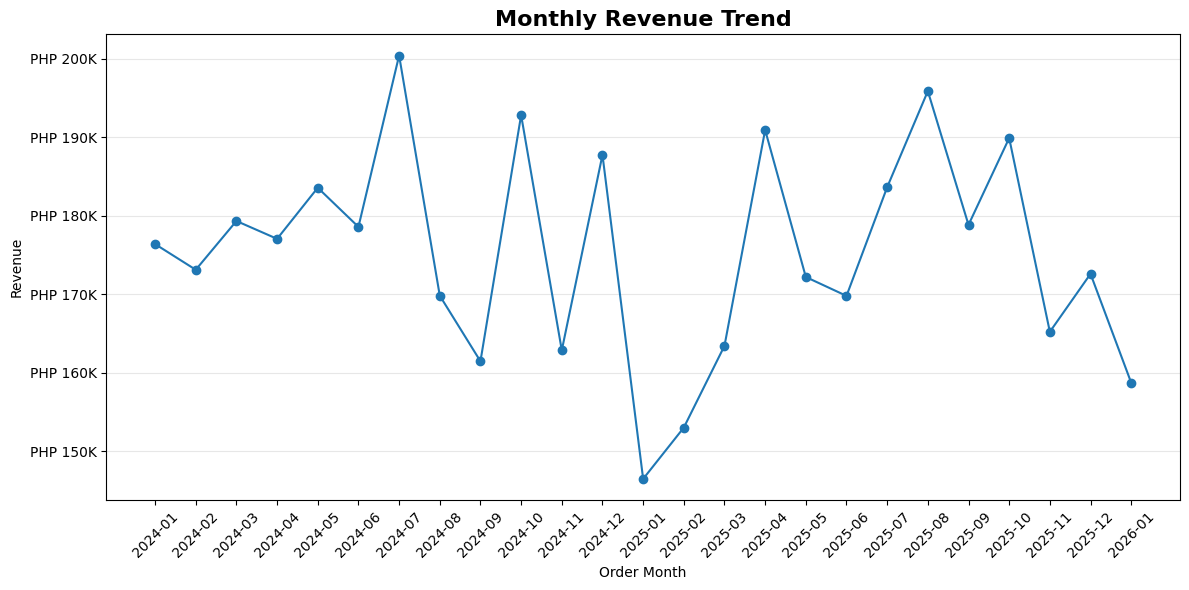

In [106]:
# --------------------------------------------------
# CHART 1 - MONTHLY REVENUE TREND
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 6)
)

ax.plot(
    monthly_revenue["order_month"],
    monthly_revenue["revenue"],
    marker="o"
)

ax.set_title(
    "Monthly Revenue Trend",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Order Month")
ax.set_ylabel("Revenue")

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"PHP {x / 1_000:.0f}K"
    )
)

ax.tick_params(
    axis="x",
    rotation=45
)

ax.grid(
    axis="y",
    alpha=0.3
)

fig.tight_layout()

fig.savefig(
    CHARTS / "01_monthly_revenue.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [107]:
chart_1_path = CHARTS / "01_monthly_revenue.png"

print("Chart exists:", chart_1_path.is_file())

if chart_1_path.is_file():
    print(
        "File size:",
        round(chart_1_path.stat().st_size / 1024, 1),
        "KB"
    )

Chart exists: True
File size: 119.8 KB


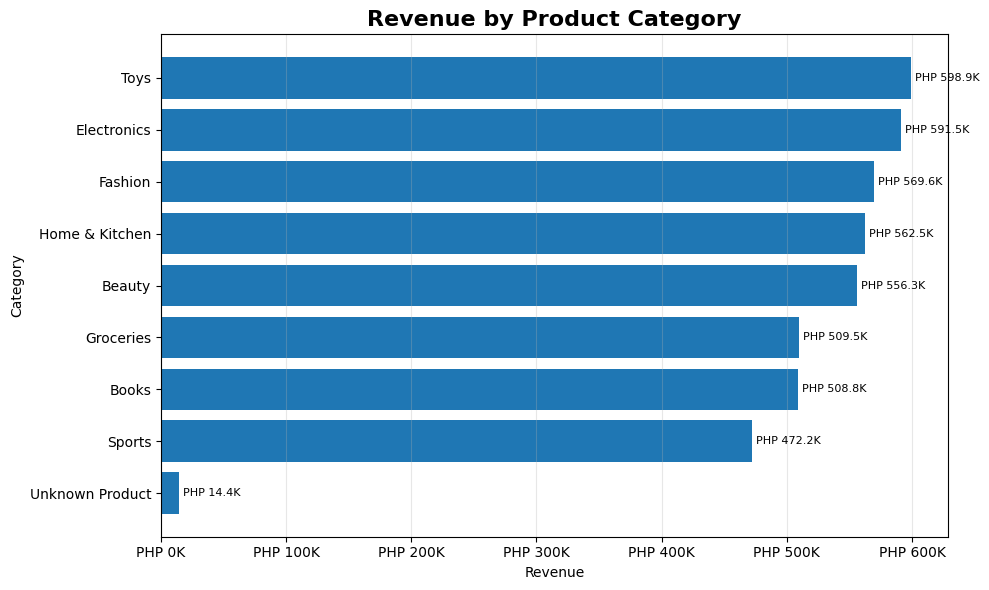

In [108]:
# --------------------------------------------------
# CHART 2 - REVENUE BY PRODUCT CATEGORY
# --------------------------------------------------

category_plot = (
    category_revenue
    .sort_values(
        "revenue",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

bars = ax.barh(
    category_plot["category_analysis"],
    category_plot["revenue"]
)

ax.set_title(
    "Revenue by Product Category",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Revenue")
ax.set_ylabel("Category")

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"PHP {x / 1_000:.0f}K"
    )
)

labels = [
    f"PHP {value / 1_000:.1f}K"
    for value in category_plot["revenue"]
]

ax.bar_label(
    bars,
    labels=labels,
    padding=3,
    fontsize=8
)

ax.grid(
    axis="x",
    alpha=0.3
)

fig.tight_layout()

fig.savefig(
    CHARTS / "02_category_revenue.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [109]:
chart_2_path = CHARTS / "02_category_revenue.png"

print("Chart exists:", chart_2_path.is_file())

if chart_2_path.is_file():
    print(
        "File size:",
        round(chart_2_path.stat().st_size / 1024, 1),
        "KB"
    )

Chart exists: True
File size: 67.9 KB


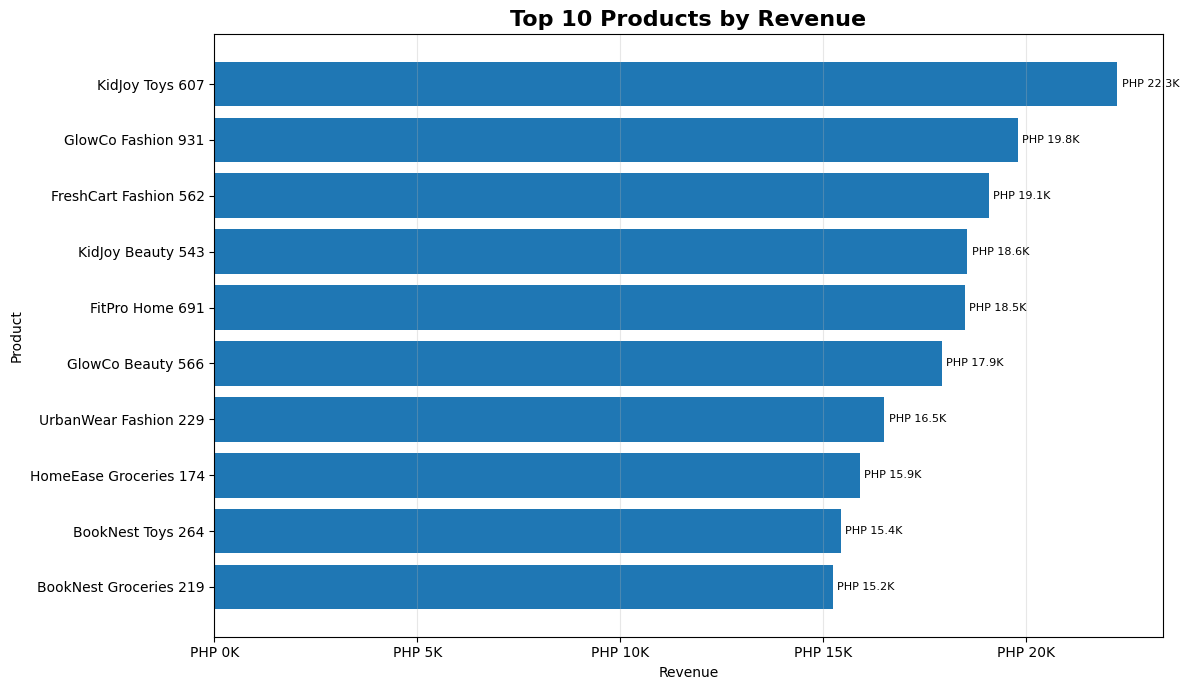

In [110]:
# --------------------------------------------------
# CHART 3 - TOP 10 PRODUCTS BY REVENUE
# --------------------------------------------------

top10_products_plot = (
    product_revenue
    .sort_values("revenue", ascending=False)
    .head(10)
    .sort_values("revenue", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top10_products_plot["product_name_analysis"],
    top10_products_plot["revenue"]
)

ax.set_title(
    "Top 10 Products by Revenue",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Revenue")
ax.set_ylabel("Product")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"PHP {x / 1000:.0f}K")
)

labels = [
    f"PHP {value / 1000:.1f}K"
    for value in top10_products_plot["revenue"]
]

ax.bar_label(
    bars,
    labels=labels,
    padding=3,
    fontsize=8
)

ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

fig.savefig(
    CHARTS / "03_top10_products_revenue.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [111]:
chart_3_path = CHARTS / "03_top10_products_revenue.png"

print("Chart exists:", chart_3_path.is_file())

if chart_3_path.is_file():
    print(
        "File size:",
        round(chart_3_path.stat().st_size / 1024, 1),
        "KB"
    )

Chart exists: True
File size: 91.4 KB


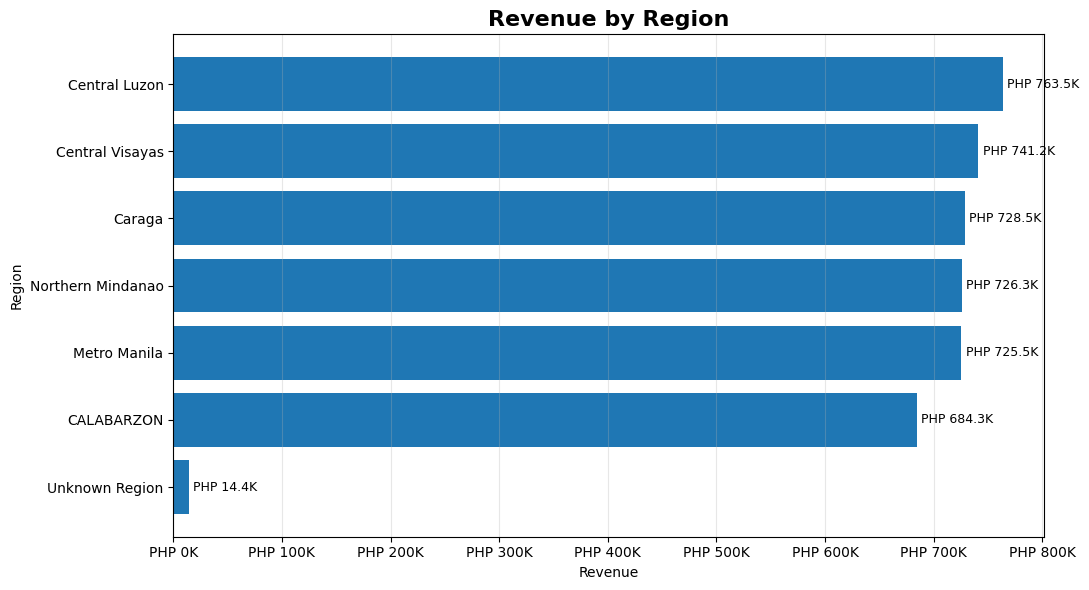

In [112]:
# --------------------------------------------------
# CHART 4 - REVENUE BY REGION
# --------------------------------------------------

region_revenue_plot = (
    region_revenue
    .sort_values("revenue", ascending=False)
    .sort_values("revenue", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    region_revenue_plot["region_analysis"],
    region_revenue_plot["revenue"]
)

ax.set_title(
    "Revenue by Region",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Revenue")
ax.set_ylabel("Region")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"PHP {x / 1000:.0f}K")
)

labels = [
    f"PHP {value / 1000:.1f}K"
    for value in region_revenue_plot["revenue"]
]

ax.bar_label(
    bars,
    labels=labels,
    padding=3,
    fontsize=9
)

ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

fig.savefig(
    CHARTS / "04_region_revenue.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [113]:
chart_4_path = CHARTS / "04_region_revenue.png"

print("Chart exists:", chart_4_path.is_file())

if chart_4_path.is_file():
    print(
        "File size:",
        round(chart_4_path.stat().st_size / 1024, 1),
        "KB"
    )

Chart exists: True
File size: 64.5 KB


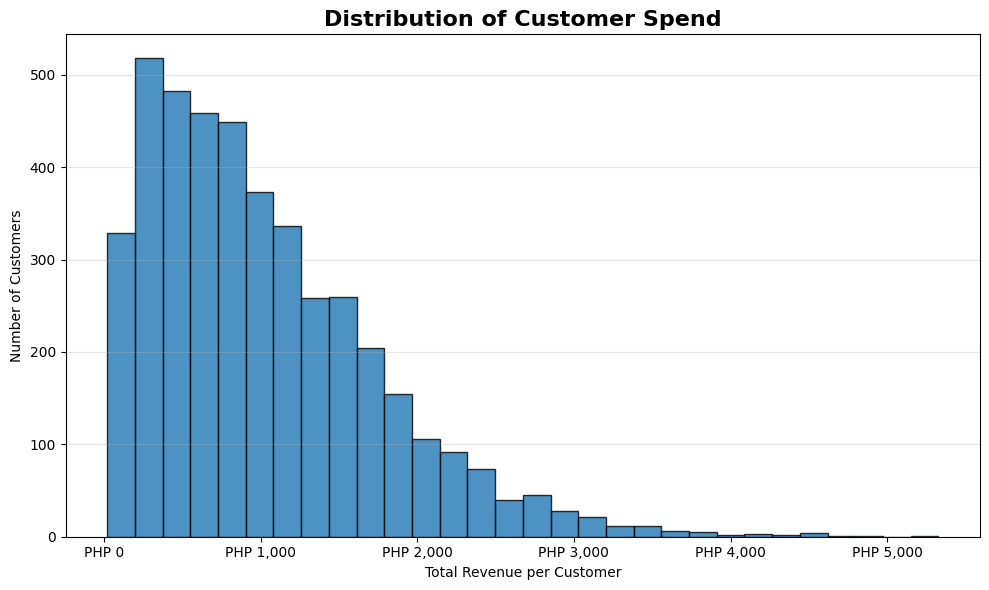

In [114]:
# --------------------------------------------------
# CHART 5 - CUSTOMER SPEND DISTRIBUTION
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.hist(
    customer_summary["revenue"],
    bins=30,
    edgecolor="black",
    alpha=0.8
)

ax.set_title(
    "Distribution of Customer Spend",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel(
    "Total Revenue per Customer"
)

ax.set_ylabel(
    "Number of Customers"
)

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"PHP {x:,.0f}"
    )
)

ax.grid(
    axis="y",
    alpha=0.3
)

fig.tight_layout()

fig.savefig(
    CHARTS / "05_customer_spend_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [115]:
chart_5_path = (
    CHARTS
    / "05_customer_spend_distribution.png"
)

print(
    "Chart exists:",
    chart_5_path.is_file()
)

if chart_5_path.is_file():

    print(
        "File size:",
        round(
            chart_5_path.stat().st_size / 1024,
            1
        ),
        "KB"
    )

Chart exists: True
File size: 45.4 KB


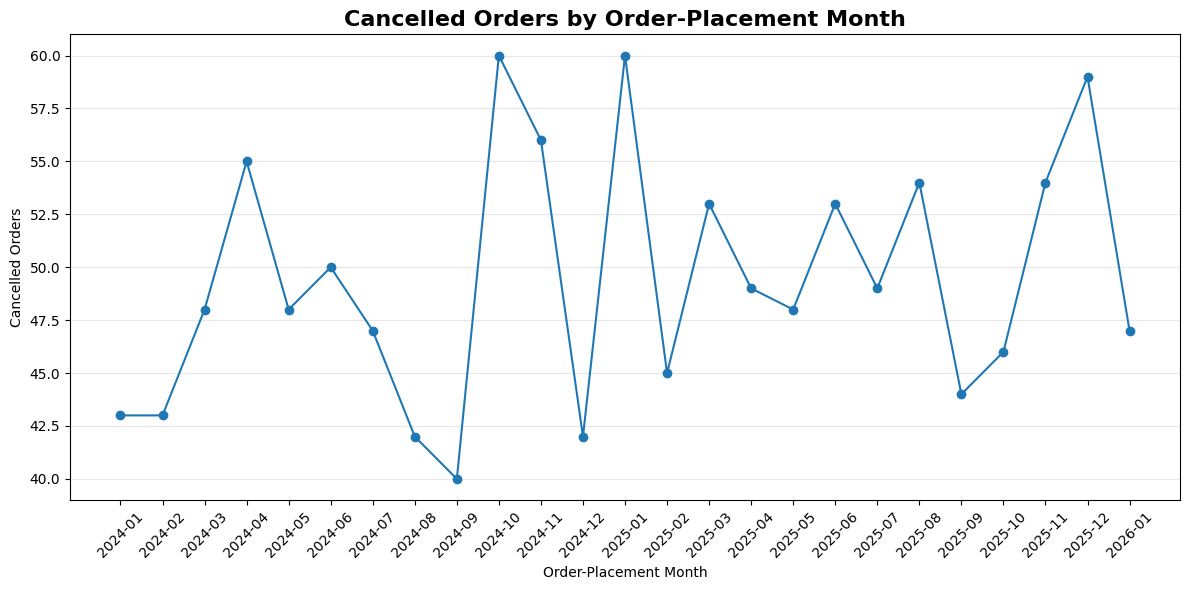

In [116]:
# --------------------------------------------------
# CHART 6 - CANCELLATION TREND
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 6)
)

ax.plot(
    cancellation_trend["order_month"],
    cancellation_trend["cancelled_orders"],
    marker="o"
)

ax.set_title(
    "Cancelled Orders by Order-Placement Month",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Order-Placement Month")
ax.set_ylabel("Cancelled Orders")

ax.tick_params(
    axis="x",
    rotation=45
)

ax.grid(
    axis="y",
    alpha=0.3
)

fig.tight_layout()

fig.savefig(
    CHARTS / "06_cancellation_trend.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [117]:
chart_6_path = (
    CHARTS
    / "06_cancellation_trend.png"
)

print(
    "Chart exists:",
    chart_6_path.is_file()
)

if chart_6_path.is_file():

    print(
        "File size:",
        round(
            chart_6_path.stat().st_size / 1024,
            1
        ),
        "KB"
    )

Chart exists: True
File size: 135.9 KB


In [118]:
# --------------------------------------------------
# STEP 17 - FINAL CHART VERIFICATION
# --------------------------------------------------

chart_files = [
    "01_monthly_revenue.png",
    "02_category_revenue.png",
    "03_top10_products_revenue.png",
    "04_region_revenue.png",
    "05_customer_spend_distribution.png",
    "06_cancellation_trend.png"
]

chart_check_rows = []

for filename in chart_files:

    path = CHARTS / filename

    chart_check_rows.append({
        "Chart": filename,
        "Exists": path.is_file(),
        "File size KB": (
            round(path.stat().st_size / 1024, 1)
            if path.is_file()
            else 0
        )
    })

chart_verification = pd.DataFrame(chart_check_rows)

display(chart_verification)

assert chart_verification["Exists"].all(), (
    "One or more required chart files are missing."
)

assert (
    chart_verification["File size KB"] > 0
).all(), (
    "One or more chart files are empty."
)

print(
    "\nChart verification passed: "
    "all six PNG charts were created successfully."
)

,Chart,Exists,File size KB
0,01_monthly_revenue.png,True,119.8
1,02_category_revenue.png,True,67.9
2,03_top10_products_revenue.png,True,91.4
3,04_region_revenue.png,True,64.5
4,05_customer_spend_distribution.png,True,45.4
5,06_cancellation_trend.png,True,135.9



Chart verification passed: all six PNG charts were created successfully.


In [119]:
chart_verification.to_csv(
    AUDIT / "step_17_chart_verification.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step 17 verification saved.")
print("\nSTEP 17 COMPLETE")

Step 17 verification saved.

STEP 17 COMPLETE


In [120]:
# --------------------------------------------------
# STEP 18A - CREATE 1920 x 1080 DASHBOARD
# --------------------------------------------------

fig = plt.figure(
    figsize=(16, 9),
    dpi=120
)

# Main dashboard title
fig.suptitle(
    "Sales Performance & Customer Insights",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

# Subtitle
fig.text(
    0.5,
    0.945,
    "Option A Capstone | Eligible Completed Orders",
    ha="center",
    fontsize=11
)

# Layout:
# row 1 = KPI cards
# row 2 = monthly + category
# row 3 = region + distribution + cancellation
gs = fig.add_gridspec(
    3,
    6,
    height_ratios=[0.8, 2.2, 2.2],
    hspace=0.55,
    wspace=0.55
)

<Figure size 1920x1080 with 0 Axes>

In [121]:
# --------------------------------------------------
# STEP 18B - KPI CARDS
# --------------------------------------------------

kpi_values = [
    (
        "Total Revenue",
        f"PHP {total_revenue:,.2f}"
    ),
    (
        "Total Orders",
        f"{total_orders:,}"
    ),
    (
        "Average Order Value",
        f"PHP {average_order_value:,.2f}"
    )
]

for i, (label, value) in enumerate(kpi_values):

    ax = fig.add_subplot(
        gs[0, i * 2:(i + 1) * 2]
    )

    ax.axis("off")

    ax.text(
        0.5,
        0.65,
        value,
        ha="center",
        va="center",
        fontsize=19,
        fontweight="bold"
    )

    ax.text(
        0.5,
        0.25,
        label,
        ha="center",
        va="center",
        fontsize=10
    )

print("KPI cards added.")

KPI cards added.


In [122]:
# --------------------------------------------------
# STEP 18C - MONTHLY REVENUE
# --------------------------------------------------

ax_monthly = fig.add_subplot(
    gs[1, 0:3]
)

ax_monthly.plot(
    monthly_revenue["order_month"],
    monthly_revenue["revenue"],
    marker="o",
    markersize=3
)

ax_monthly.set_title(
    "Monthly Revenue",
    fontsize=12,
    fontweight="bold"
)

ax_monthly.set_ylabel("Revenue")

ax_monthly.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"PHP {x / 1_000:.0f}K"
    )
)

# Show every second month to reduce crowding
ax_monthly.set_xticks(
    range(
        0,
        len(monthly_revenue),
        2
    )
)

ax_monthly.set_xticklabels(
    monthly_revenue["order_month"].iloc[::2],
    rotation=45,
    ha="right",
    fontsize=7
)

ax_monthly.grid(
    axis="y",
    alpha=0.3
)

In [123]:
# --------------------------------------------------
# STEP 18D - CATEGORY REVENUE
# --------------------------------------------------

dashboard_categories = (
    category_revenue
    .sort_values(
        "revenue",
        ascending=True
    )
)

ax_category = fig.add_subplot(
    gs[1, 3:6]
)

ax_category.barh(
    dashboard_categories["category_analysis"],
    dashboard_categories["revenue"]
)

ax_category.set_title(
    "Revenue by Category",
    fontsize=12,
    fontweight="bold"
)

ax_category.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"PHP {x / 1_000:.0f}K"
    )
)

ax_category.tick_params(
    axis="y",
    labelsize=7
)

ax_category.grid(
    axis="x",
    alpha=0.3
)

In [124]:
# --------------------------------------------------
# STEP 18E - REGION REVENUE
# --------------------------------------------------

dashboard_regions = (
    region_revenue
    .sort_values(
        "revenue",
        ascending=True
    )
)

ax_region = fig.add_subplot(
    gs[2, 0:2]
)

ax_region.barh(
    dashboard_regions["region_analysis"],
    dashboard_regions["revenue"]
)

ax_region.set_title(
    "Revenue by Region",
    fontsize=11,
    fontweight="bold"
)

ax_region.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"{x / 1_000:.0f}K"
    )
)

ax_region.tick_params(
    axis="y",
    labelsize=7
)

ax_region.grid(
    axis="x",
    alpha=0.3
)

In [125]:
# --------------------------------------------------
# STEP 18F - CUSTOMER SPEND DISTRIBUTION
# --------------------------------------------------

ax_spend = fig.add_subplot(
    gs[2, 2:4]
)

ax_spend.hist(
    customer_summary["revenue"],
    bins=25
)

ax_spend.set_title(
    "Customer Spend Distribution",
    fontsize=11,
    fontweight="bold"
)

ax_spend.set_xlabel(
    "Customer Spend",
    fontsize=8
)

ax_spend.set_ylabel(
    "Customers",
    fontsize=8
)

ax_spend.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"{x / 1_000:.1f}K"
    )
)

ax_spend.grid(
    axis="y",
    alpha=0.3
)

In [126]:
# --------------------------------------------------
# STEP 18G - CANCELLATION TREND
# --------------------------------------------------

ax_cancel = fig.add_subplot(
    gs[2, 4:6]
)

ax_cancel.plot(
    cancellation_trend["order_month"],
    cancellation_trend["cancelled_orders"],
    marker="o",
    markersize=3
)

ax_cancel.set_title(
    "Cancelled Orders",
    fontsize=11,
    fontweight="bold"
)

ax_cancel.set_ylabel(
    "Orders",
    fontsize=8
)

ax_cancel.set_xticks(
    range(
        0,
        len(cancellation_trend),
        3
    )
)

ax_cancel.set_xticklabels(
    cancellation_trend["order_month"].iloc[::3],
    rotation=45,
    ha="right",
    fontsize=7
)

ax_cancel.grid(
    axis="y",
    alpha=0.3
)

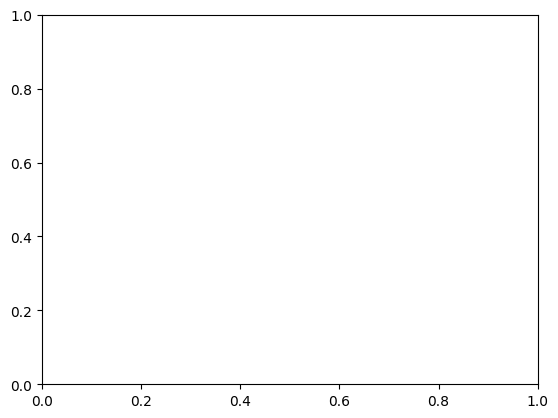

Dashboard saved to:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/charts/Option_A_Dashboard_1920x1080.png


In [127]:
# --------------------------------------------------
# STEP 18H - SAVE EXACT 1920 x 1080 DASHBOARD
# --------------------------------------------------

dashboard_path = (
    CHARTS
    / "Option_A_Dashboard_1920x1080.png"
)

fig.savefig(
    dashboard_path,
    dpi=120
)

plt.show()

print("Dashboard saved to:")
print(dashboard_path)

In [128]:
from PIL import Image

with Image.open(dashboard_path) as img:

    dashboard_width, dashboard_height = img.size

print(
    "Dashboard dimensions:",
    dashboard_width,
    "x",
    dashboard_height
)

assert dashboard_width == 1920, (
    "Dashboard width is not 1920 pixels."
)

assert dashboard_height == 1080, (
    "Dashboard height is not 1080 pixels."
)

print(
    "Dashboard dimension check passed: "
    "1920 x 1080."
)

Dashboard dimensions: 1920 x 1080
Dashboard dimension check passed: 1920 x 1080.


In [129]:
# --------------------------------------------------
# STEP 18I - FINAL VISUALIZATION CHECK
# --------------------------------------------------

visual_files = [
    "01_monthly_revenue.png",
    "02_category_revenue.png",
    "03_top10_products_revenue.png",
    "04_region_revenue.png",
    "05_customer_spend_distribution.png",
    "06_cancellation_trend.png",
    "Option_A_Dashboard_1920x1080.png"
]

visual_check = []

for filename in visual_files:

    file_path = CHARTS / filename

    visual_check.append({
        "File": filename,
        "Exists": file_path.is_file(),
        "Size KB": (
            round(
                file_path.stat().st_size
                / 1024,
                1
            )
            if file_path.is_file()
            else 0
        )
    })

visual_verification = pd.DataFrame(
    visual_check
)

display(visual_verification)

assert visual_verification["Exists"].all()

print(
    "\nAll visualization deliverables verified."
)

,File,Exists,Size KB
0,01_monthly_revenue.png,True,119.8
1,02_category_revenue.png,True,67.9
2,03_top10_products_revenue.png,True,91.4
3,04_region_revenue.png,True,64.5
4,05_customer_spend_distribution.png,True,45.4
5,06_cancellation_trend.png,True,135.9
6,Option_A_Dashboard_1920x1080.png,True,176.5



All visualization deliverables verified.


In [130]:
from matplotlib.ticker import MaxNLocator

Logo found successfully:
/mnt/data/python_capstone_build/case-studies/python-capstone/assets/DSA_LOGO_CIRCLE_OFFICIAL.png


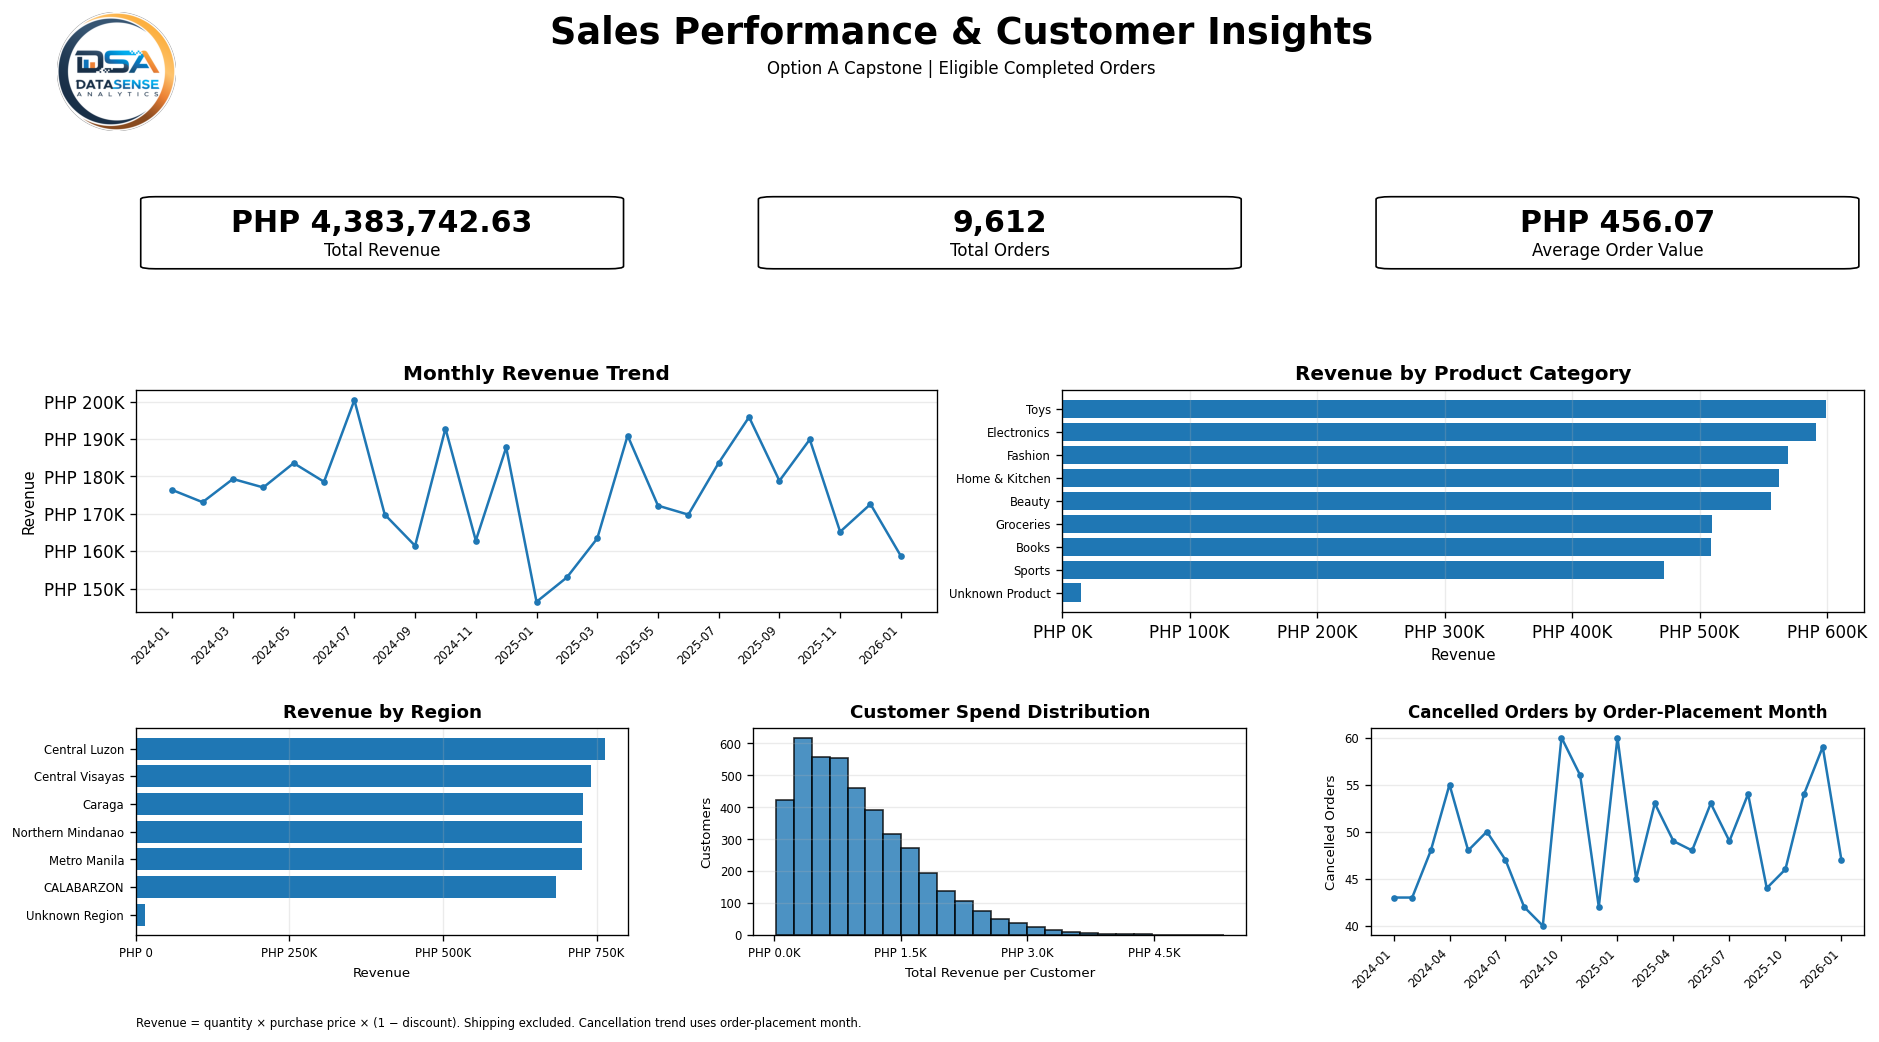


Dashboard saved successfully:
/mnt/data/python_capstone_build/case-studies/python-capstone/outputs/charts/Option_A_Dashboard_1920x1080.png

Dashboard dimensions: 1920 x 1080
Dashboard dimension check passed: 1920 x 1080.


In [131]:
# ============================================================
# STEP 18 - FINAL POLISHED DASHBOARD WITH DATASENSE LOGO
# ============================================================

from pathlib import Path
from PIL import Image
from matplotlib.patches import FancyBboxPatch


# ------------------------------------------------------------
# 1. FIND THE DATASENSE LOGO
# ------------------------------------------------------------

ASSETS = ROOT / "assets"

# First try the exact expected filename
exact_logo = ASSETS / "DSA_LOGO_CIRCLE_OFFICIAL.png"

if exact_logo.is_file():
    LOGO = exact_logo

else:
    # If exact filename is not found, search all PNG files
    png_files = list(ASSETS.glob("*.png"))

    logo_matches = [
        file
        for file in png_files
        if "DSA" in file.stem.upper()
        and "LOGO" in file.stem.upper()
    ]

    if logo_matches:
        LOGO = logo_matches[0]
    else:
        print("PNG files found in assets folder:")
        for file in png_files:
            print("-", file.name)

        raise FileNotFoundError(
            "DataSense logo could not be found inside the assets folder."
        )


print("Logo found successfully:")
print(LOGO)


# ------------------------------------------------------------
# 2. CREATE 1920 x 1080 FIGURE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(16, 9),
    dpi=120
)

# Dashboard layout
gs = fig.add_gridspec(
    3,
    6,
    height_ratios=[
        0.85,
        2.25,
        2.10
    ],
    left=0.07,
    right=0.97,
    top=0.81,
    bottom=0.12,
    hspace=0.68,
    wspace=0.68
)


# ------------------------------------------------------------
# 3. HEADER
# ------------------------------------------------------------

fig.text(
    0.50,
    0.955,
    "Sales Performance & Customer Insights",
    ha="center",
    va="center",
    fontsize=22,
    fontweight="bold"
)

fig.text(
    0.50,
    0.922,
    "Option A Capstone | Eligible Completed Orders",
    ha="center",
    va="center",
    fontsize=10
)


# ------------------------------------------------------------
# 4. INSERT DATASENSE LOGO
# ------------------------------------------------------------

logo_img = plt.imread(LOGO)

logo_ax = fig.add_axes(
    [
        0.025,   # left
        0.865,   # bottom
        0.070,   # width
        0.110    # height
    ]
)

logo_ax.imshow(logo_img)
logo_ax.axis("off")


# ------------------------------------------------------------
# 5. KPI CARDS
# ------------------------------------------------------------

kpi_values = [
    (
        "Total Revenue",
        f"PHP {total_revenue:,.2f}"
    ),
    (
        "Total Orders",
        f"{total_orders:,}"
    ),
    (
        "Average Order Value",
        f"PHP {average_order_value:,.2f}"
    )
]

for i, (label, value) in enumerate(kpi_values):

    ax = fig.add_subplot(
        gs[0, i * 2:(i + 1) * 2]
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # KPI card
    card = FancyBboxPatch(
        (0.03, 0.08),
        0.94,
        0.82,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        fill=False,
        linewidth=1.0
    )

    ax.add_patch(card)

    ax.text(
        0.50,
        0.60,
        value,
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold"
    )

    ax.text(
        0.50,
        0.28,
        label,
        ha="center",
        va="center",
        fontsize=10
    )


# ------------------------------------------------------------
# 6. MONTHLY REVENUE TREND
# ------------------------------------------------------------

ax_monthly = fig.add_subplot(
    gs[1, 0:3]
)

ax_monthly.plot(
    monthly_revenue["order_month"],
    monthly_revenue["revenue"],
    marker="o",
    markersize=3
)

ax_monthly.set_title(
    "Monthly Revenue Trend",
    fontsize=12,
    fontweight="bold"
)

ax_monthly.set_ylabel(
    "Revenue",
    fontsize=9
)

ax_monthly.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"PHP {x / 1000:.0f}K"
    )
)

# Reduce crowded month labels
monthly_positions = list(
    range(
        0,
        len(monthly_revenue),
        2
    )
)

ax_monthly.set_xticks(
    monthly_positions
)

ax_monthly.set_xticklabels(
    monthly_revenue[
        "order_month"
    ].iloc[::2],
    rotation=45,
    ha="right",
    fontsize=7
)

ax_monthly.grid(
    axis="y",
    alpha=0.25
)


# ------------------------------------------------------------
# 7. REVENUE BY PRODUCT CATEGORY
# ------------------------------------------------------------

dashboard_categories = (
    category_revenue
    .sort_values(
        "revenue",
        ascending=True
    )
)

ax_category = fig.add_subplot(
    gs[1, 3:6]
)

category_bars = ax_category.barh(
    dashboard_categories[
        "category_analysis"
    ],
    dashboard_categories[
        "revenue"
    ]
)

ax_category.set_title(
    "Revenue by Product Category",
    fontsize=12,
    fontweight="bold"
)

ax_category.set_xlabel(
    "Revenue",
    fontsize=9
)

ax_category.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"PHP {x / 1000:.0f}K"
    )
)

ax_category.tick_params(
    axis="y",
    labelsize=7
)

ax_category.grid(
    axis="x",
    alpha=0.25
)


# ------------------------------------------------------------
# REVENUE BY REGION
# ------------------------------------------------------------

dashboard_regions = (
    region_revenue
    .sort_values(
        "revenue",
        ascending=True
    )
)

ax_region = fig.add_subplot(
    gs[2, 0:2]
)

ax_region.barh(
    dashboard_regions["region_analysis"],
    dashboard_regions["revenue"]
)

ax_region.set_title(
    "Revenue by Region",
    fontsize=11,
    fontweight="bold"
)

ax_region.set_xlabel(
    "Revenue",
    fontsize=8
)

# Limit number of x-axis labels
ax_region.xaxis.set_major_locator(
    MaxNLocator(nbins=4)
)

ax_region.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        "PHP 0"
        if x == 0
        else f"PHP {x / 1000:.0f}K"
    )
)

ax_region.tick_params(
    axis="x",
    labelsize=7
)

ax_region.tick_params(
    axis="y",
    labelsize=7
)

ax_region.grid(
    axis="x",
    alpha=0.25
)


# ------------------------------------------------------------
# CUSTOMER SPEND DISTRIBUTION
# ------------------------------------------------------------

ax_spend = fig.add_subplot(
    gs[2, 2:4]
)

ax_spend.hist(
    customer_summary["revenue"],
    bins=25,
    edgecolor="black",
    alpha=0.80
)

ax_spend.set_title(
    "Customer Spend Distribution",
    fontsize=11,
    fontweight="bold"
)

ax_spend.set_xlabel(
    "Total Revenue per Customer",
    fontsize=8
)

ax_spend.set_ylabel(
    "Customers",
    fontsize=8
)

# Reduce x-axis tick crowding
ax_spend.xaxis.set_major_locator(
    MaxNLocator(nbins=5)
)

ax_spend.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos:
        f"PHP {x / 1000:.1f}K"
    )
)

ax_spend.tick_params(
    axis="x",
    labelsize=7
)

ax_spend.tick_params(
    axis="y",
    labelsize=7
)

ax_spend.grid(
    axis="y",
    alpha=0.25
)

# ------------------------------------------------------------
# CANCELLATION TREND
# ------------------------------------------------------------

ax_cancel = fig.add_subplot(
    gs[2, 4:6]
)

ax_cancel.plot(
    cancellation_trend["order_month"],
    cancellation_trend["cancelled_orders"],
    marker="o",
    markersize=3
)

ax_cancel.set_title(
    "Cancelled Orders by Order-Placement Month",
    fontsize=10,
    fontweight="bold"
)

ax_cancel.set_ylabel(
    "Cancelled Orders",
    fontsize=8
)

cancel_positions = list(
    range(
        0,
        len(cancellation_trend),
        3
    )
)

ax_cancel.set_xticks(
    cancel_positions
)

ax_cancel.set_xticklabels(
    cancellation_trend["order_month"].iloc[::3],
    rotation=45,
    ha="right",
    fontsize=7
)

ax_cancel.tick_params(
    axis="y",
    labelsize=7
)

ax_cancel.grid(
    axis="y",
    alpha=0.25
)


# ------------------------------------------------------------
# 11. DASHBOARD FOOTNOTE
# ------------------------------------------------------------

fig.text(
    0.07,
    0.035,
    (
        "Revenue = quantity × purchase price × (1 − discount). "
        "Shipping excluded. "
        "Cancellation trend uses order-placement month."
    ),
    fontsize=7,
    ha="left"
)


# ------------------------------------------------------------
# 12. SAVE DASHBOARD
# ------------------------------------------------------------

dashboard_path = (
    CHARTS
    / "Option_A_Dashboard_1920x1080.png"
)

# IMPORTANT:
# Do not use bbox_inches='tight' because we want
# exactly 1920 x 1080 pixels.
fig.savefig(
    dashboard_path,
    dpi=120
)

plt.show()

print("\nDashboard saved successfully:")
print(dashboard_path)


# ------------------------------------------------------------
# 13. VERIFY IMAGE DIMENSIONS
# ------------------------------------------------------------

with Image.open(dashboard_path) as img:

    dashboard_width, dashboard_height = img.size

print(
    "\nDashboard dimensions:",
    dashboard_width,
    "x",
    dashboard_height
)

assert (
    dashboard_width == 1920
    and dashboard_height == 1080
), (
    "Dashboard dimensions are not 1920 x 1080."
)

print(
    "Dashboard dimension check passed: "
    "1920 x 1080."
)

## Key Insights

1. **Overall sales performance**
   - Eligible completed orders generated PHP 4.38 million in revenue from 9,612 orders, with an average order value of PHP 456.07.

2. **Monthly revenue fluctuated throughout the period**
   - Monthly revenue did not follow a consistent upward or downward pattern. July 2024 recorded the highest revenue at about PHP 200.4K, while January 2025 recorded the lowest at about PHP 146.5K.

3. **Revenue is distributed across several product categories**
   - Toys generated the highest category revenue at about PHP 598.9K or 13.7% of total revenue. Electronics followed closely at about PHP 591.5K.
   - No single category dominated total sales, which shows that revenue is spread across multiple product groups.

4. **Top-selling individual products contribute a relatively small share of total revenue**
   - KidJoy Toys 607 was the highest-revenue product at about PHP 22.3K.
   - The contribution of each top product is relatively small compared with total company revenue, indicating that sales are distributed across a broad product assortment.

5. **Central Luzon generated the highest regional revenue**
   - Central Luzon contributed about PHP 763.5K or 17.4% of total revenue.
   - Central Visayas, Caraga, Northern Mindanao, and Metro Manila followed closely, showing relatively balanced revenue contribution among the major regions.

6. **Repeat customers are the main source of customer revenue**
   - Repeat customers represented about 67.2% of matched customers and generated approximately 85.4% of matched-customer revenue.
   - New customers represented about 32.8% of matched customers but accounted for a much smaller portion of revenue.

7. **Customer spending is right-skewed**
   - Most matched customers are concentrated at the lower end of total spend, while a smaller number of customers generated substantially higher cumulative revenue.

8. **Cancellation levels vary by month**
   - There were 1,235 cancelled orders, equivalent to an overall cancellation rate of 8.23%.
   - October 2024 and January 2025 recorded the highest cancellation count at 60 orders each, while January 2025 had the highest monthly cancellation rate at 10.77%.

## Recommendations

1. **Strengthen repeat-customer retention and increase value from new customers**
   - Repeat customers already generate most customer revenue. Maintain retention efforts for this group while using targeted follow-up, cross-selling, or repeat-purchase offers to move more one-order customers into the repeat segment.

2. **Review months and segments with elevated cancellations**
   - Investigate the causes behind the cancellation peaks, particularly January 2025 and other high-rate months. Review product availability, fulfillment issues, customer behavior, and order-processing factors to identify actions that can reduce avoidable cancellations.

## Analysis Notes

- Revenue was calculated as quantity × unit price at purchase × (1 - discount).
- Shipping fees were excluded from merchandise revenue.
- Only Completed orders without unresolved item-quality issues were included in the sales KPIs.
- New customers were defined as matched customers with one eligible order in the observed dataset. Repeat customers had two or more eligible orders.
- The cancellation trend uses the original order-placement month because a separate cancellation date was not available.
- Unknown product and customer-location groups were retained in aggregated results so their revenue was not silently removed.